# 01 · Análisis exploratorio de datos (EDA): Predict Future Sales

**Dataset:** ventas diarias de 1C Company, una cadena rusa de tiendas de software, videojuegos, cine, música y regalos (Kaggle).
**Objetivo del proyecto:** predecir las unidades vendidas por cada par tienda-producto en **noviembre de 2015** (`date_block_num = 34`).
**Objetivo de este notebook:** entender la estructura, la calidad y el comportamiento temporal de los datos para preparar la etapa de forecasting.

**Contenido**

1. Estructura del proyecto y repositorio
2. Comprensión inicial del dataset
3. Validación de la estructura de los datos
4. Valores faltantes, inválidos y duplicados
5. Análisis descriptivo general
6. Exploración temporal
7. Análisis comparativo entre sucursales y productos
8. Visualizaciones clave
9. Autocorrelación (ACF) y autocorrelación parcial (PACF)
10. Insights y conclusiones

## 1. Estructura del proyecto y repositorio

- **Estructura:** plantilla Cookiecutter Data Science v2 (`ccds`), con el paquete `future_sales`. Las rutas se leen siempre desde `future_sales.config` (`RAW_DATA_DIR`, `EXTERNAL_DATA_DIR`), nunca con rutas relativas al notebook.
- **Datos:** los CSV originales de Kaggle están en `data/raw/`. Las traducciones al español de tiendas y categorías, hechas a mano, están en `data/external/`.
- **Repositorio:** git local en la rama `main`. El `.gitignore` excluye `data/**` (los datos pesan ~100 MB) y `models/*`, pero conserva los `.gitkeep` y las traducciones `data/external/*_traducido.csv`.
- **Entorno:** conda `env_future_sales` (Python 3.11, BLAS en OpenBLAS), con las versiones fijadas en `requirements.txt`.

### Configuración

Librerías, opciones de visualización y rutas del proyecto.

In [1]:
import re

from IPython.display import display
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
import seaborn as sns
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import acf, adfuller, pacf

from future_sales.config import EXTERNAL_DATA_DIR, RAW_DATA_DIR

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", "{:,.2f}".format)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (12, 4.5)
plt.rcParams["axes.titleweight"] = "bold"

COLOR = "#2a6f97"
COLOR_ALT = "#e07a5f"
MILES = mtick.FuncFormatter(lambda x, _: f"{x / 1e3:,.0f}k")
MILLONES = mtick.FuncFormatter(lambda x, _: f"{x / 1e6:,.0f}M")

2026-11-11 11:54:21.417 | INFO     | future_sales.config:<module>:11 - PROJ_ROOT path is: C:\Users\rfarfan\OneDrive - Universidad Galileo\2026T4\Product Development\Proyecto\future-sales


## 2. Comprensión inicial del dataset

### 2.1 Carga de los archivos

Se leen los cinco CSV desde `RAW_DATA_DIR`. En `test.csv` la columna `ID` es el identificador de fila, así que se usa como índice.

In [2]:
ventas_raw = pd.read_csv(RAW_DATA_DIR / "sales_train.csv")
items = pd.read_csv(RAW_DATA_DIR / "items.csv")
categorias = pd.read_csv(RAW_DATA_DIR / "item_categories.csv")
tiendas = pd.read_csv(RAW_DATA_DIR / "shops.csv")
test = pd.read_csv(RAW_DATA_DIR / "test.csv", index_col="ID")

tablas = {
    "sales_train": ventas_raw,
    "items": items,
    "item_categories": categorias,
    "shops": tiendas,
    "test": test,
}

### 2.2 Primeras filas de cada tabla

In [3]:
for nombre, df in tablas.items():
    print(f"── {nombre}")
    display(df.head())

── sales_train


,date,date_block_num,shop_id,item_id,item_price,item_cnt_day
0,02.01.2013,0,59,22154,999.00,1.00
1,03.01.2013,0,25,2552,899.00,1.00
2,05.01.2013,0,25,2552,899.00,-1.00
3,06.01.2013,0,25,2554,"1,709.05",1.00
4,15.01.2013,0,25,2555,"1,099.00",1.00


── items


,item_name,item_id,item_category_id
0,! ВО ВЛАСТИ НАВАЖДЕНИЯ (ПЛАСТ.) D,0,40
1,!ABBYY FineReader 12 Professional Edition Full...,1,76
2,***В ЛУЧАХ СЛАВЫ (UNV) D,2,40
3,***ГОЛУБАЯ ВОЛНА (Univ) D,3,40
4,***КОРОБКА (СТЕКЛО) D,4,40


── item_categories


,item_category_name,item_category_id
0,PC - Гарнитуры/Наушники,0
1,Аксессуары - PS2,1
2,Аксессуары - PS3,2
3,Аксессуары - PS4,3
4,Аксессуары - PSP,4


── shops


,shop_name,shop_id
0,"!Якутск Орджоникидзе, 56 фран",0
1,"!Якутск ТЦ ""Центральный"" фран",1
2,"Адыгея ТЦ ""Мега""",2
3,"Балашиха ТРК ""Октябрь-Киномир""",3
4,"Волжский ТЦ ""Волга Молл""",4


── test


,shop_id,item_id
ID,,
0,5,5037
1,5,5320
2,5,5233
3,5,5232
4,5,5268


### 2.3 Tamaño de cada tabla

Número de filas y columnas, y memoria que ocupa cada tabla.

In [4]:
tamanos = pd.DataFrame(
    {
        nombre: {
            "filas": df.shape[0],
            "columnas": df.shape[1],
            "memoria_MB": df.memory_usage(deep=True).sum() / 1e6,
        }
        for nombre, df in tablas.items()
    }
).T.astype({"filas": int, "columnas": int})
tamanos

,filas,columnas,memoria_MB
sales_train,2935849,6,314.14
items,22170,3,3.84
item_categories,84,2,0.01
shops,60,2,0.01
test,214200,2,3.43


### 2.4 Descripción de las columnas y variable objetivo

| Columna | Tabla | Qué representa |
|---|---|---|
| `date` | sales_train | Fecha de la transacción (texto `dd.mm.aaaa`). |
| `date_block_num` | sales_train | Número de mes consecutivo: 0 = enero 2013, …, 33 = octubre 2015. |
| `shop_id` | sales_train, shops, test | Identificador de la tienda (sucursal). |
| `item_id` | sales_train, items, test | Identificador del producto. |
| `item_price` | sales_train | Precio unitario de venta en ese registro (rublos). |
| `item_cnt_day` | sales_train | Unidades vendidas ese día; los negativos son devoluciones. |
| `item_name` | items | Nombre del producto (en ruso). |
| `item_category_id` | items, item_categories | Identificador de la categoría del producto. |
| `item_category_name` | item_categories | Nombre de la categoría (en ruso, formato `Grupo - Plataforma/Subtipo`). |
| `shop_name` | shops | Nombre de la tienda (en ruso, empieza con la ciudad). |
| `ID` | test | Identificador de cada par tienda-producto que se debe predecir. |

**Variable objetivo:** `item_cnt_month`, las unidades vendidas por un par tienda-producto en un mes. No viene en los datos: se construye sumando `item_cnt_day` por (`date_block_num`, `shop_id`, `item_id`). Las ventas en dinero tampoco vienen y se construyen como `ingreso = item_price × item_cnt_day`.

> En Kaggle el target se recorta a [0, 20] y se evalúa con RMSE. Si se recorta o no, se decide en la fase 2; en este EDA se muestran ambas versiones donde importa.

### 2.5 Rango temporal

Fecha mínima y máxima, número de días calendario y meses cubiertos.

In [5]:
fechas = pd.to_datetime(ventas_raw["date"], format="%d.%m.%Y")
bloques = ventas_raw["date_block_num"]
print(f"Fecha mínima : {fechas.min():%d-%m-%Y}")
print(f"Fecha máxima : {fechas.max():%d-%m-%Y}")
print(f"Días calendario: {(fechas.max() - fechas.min()).days + 1:,}")
print(
    f"Meses cubiertos: {bloques.nunique()} "
    f"(date_block_num {bloques.min()} a {bloques.max()})"
)

Fecha mínima : 01-01-2013
Fecha máxima : 31-10-2015
Días calendario: 1,034
Meses cubiertos: 34 (date_block_num 0 a 33)


## 3. Validación de la estructura de los datos

### 3.1 Tipos de datos

Tipo de pandas de cada columna y su tipo semántico. Los `*_id` llegan como enteros, pero son **códigos categóricos**: su valor numérico no tiene orden ni magnitud.

In [6]:
TIPO_SEMANTICO = {
    "date": "fecha (llega como texto)",
    "date_block_num": "temporal (índice de mes)",
    "shop_id": "categórica (código)",
    "item_id": "categórica (código)",
    "item_category_id": "categórica (código)",
    "item_price": "numérica continua",
    "item_cnt_day": "numérica discreta",
    "item_name": "texto libre",
    "item_category_name": "categórica (texto)",
    "shop_name": "categórica (texto)",
}
tipos = pd.DataFrame(
    [
        {
            "tabla": nombre,
            "columna": col,
            "dtype": str(df[col].dtype),
            "valores_unicos": df[col].nunique(),
            "tipo_semantico": TIPO_SEMANTICO.get(col),
        }
        for nombre, df in tablas.items()
        for col in df.columns
    ]
)
tipos

,tabla,columna,dtype,valores_unicos,tipo_semantico
0,sales_train,date,str,1034,fecha (llega como texto)
1,sales_train,date_block_num,int64,34,temporal (índice de mes)
2,sales_train,shop_id,int64,60,categórica (código)
3,sales_train,item_id,int64,21807,categórica (código)
4,sales_train,item_price,float64,19993,numérica continua
5,sales_train,item_cnt_day,float64,198,numérica discreta
6,items,item_name,str,22170,texto libre
7,items,item_id,int64,22170,categórica (código)
8,items,item_category_id,int64,84,categórica (código)
9,item_categories,item_category_name,str,84,categórica (texto)


### 3.2 Conversión de `date` a datetime

En el archivo, `date` es texto con formato `dd.mm.aaaa`. Se convierte con el formato explícito y `errors="coerce"`, y se verifica que ninguna fecha haya quedado nula.

In [7]:
print("Tipo original:", ventas_raw["date"].dtype,
      "| ejemplo:", ventas_raw["date"].iloc[0])
ventas = ventas_raw.copy()
ventas["date"] = pd.to_datetime(
    ventas["date"], format="%d.%m.%Y", errors="coerce"
)
print("Tipo nuevo   :", ventas["date"].dtype)
print("Fechas no convertidas:", ventas["date"].isna().sum())

Tipo original: str | ejemplo: 02.01.2013
Tipo nuevo   : datetime64[us]
Fechas no convertidas: 0


### 3.3 Frecuencia temporal

Se revisa:

- si hay días del calendario sin ninguna venta;
- si `date_block_num` coincide con el mes de `date`;
- qué tan densas son las series tienda-producto en cada granularidad (diaria, semanal y mensual): el porcentaje de celdas con al menos una venta.

In [8]:
calendario = pd.date_range(ventas["date"].min(), ventas["date"].max(),
                           freq="D")
dias_con_venta = pd.DatetimeIndex(ventas["date"].unique())
dias_sin_venta = calendario.difference(dias_con_venta)
print(f"Días del calendario: {len(calendario):,} | con ventas: "
      f"{len(dias_con_venta):,} | sin ventas: {len(dias_sin_venta)}")

bloque_calculado = (
    (ventas["date"].dt.year - 2013) * 12 + ventas["date"].dt.month - 1
)
print("Filas con date_block_num inconsistente:",
      (bloque_calculado != ventas["date_block_num"]).sum())

dias_por_mes = ventas.groupby("date_block_num")["date"].nunique()
print("Días con ventas por mes: mín", dias_por_mes.min(),
      "| máx", dias_por_mes.max())

semana = ventas["date"].dt.to_period("W")
n_pares = len(ventas[["shop_id", "item_id"]].drop_duplicates())
densidad = pd.Series(
    {
        "diaria": len(ventas[["date", "shop_id", "item_id"]]
                      .drop_duplicates()) / (len(calendario) * n_pares),
        "semanal": len(ventas.assign(semana=semana)
                       [["semana", "shop_id", "item_id"]]
                       .drop_duplicates()) / (semana.nunique() * n_pares),
        "mensual": len(ventas[["date_block_num", "shop_id", "item_id"]]
                       .drop_duplicates()) / (34 * n_pares),
    },
    name="% celdas tienda-producto con venta",
) * 100
densidad.round(2).to_frame()

Días del calendario: 1,034 | con ventas: 1,034 | sin ventas: 0
Filas con date_block_num inconsistente: 0
Días con ventas por mes: mín 28 | máx 31


,% celdas tienda-producto con venta
diaria,0.67
semanal,3.69
mensual,11.16


**Conclusión sobre la frecuencia**

- Los 1,034 días del periodo tienen ventas (no hay huecos en el calendario), y `date_block_num` coincide con el mes de `date` en el 100 % de las filas.
- A nivel tienda-producto, la serie diaria es extremadamente dispersa: solo el **0.67 %** de las celdas día-tienda-producto tiene alguna venta, contra el 3.7 % semanal y el **11.2 %** mensual.
- El objetivo (noviembre 2015) y `test.csv` están definidos por mes.

**Por lo tanto, conviene agregar a frecuencia mensual.** La frecuencia diaria se usa solo para la serie total (ciclo semanal) y para features de calendario. La semanal no aporta: las semanas cruzan los límites de mes y no coinciden con el target.

### 3.4 Textos en alfabeto cirílico

`shop_name`, `item_category_name` e `item_name` están en ruso. Opciones evaluadas:

| Opción | Ventaja | Desventaja |
|---|---|---|
| **Traducción manual de los catálogos pequeños** (elegida) | Traducción exacta de 60 tiendas y 84 categorías; permite derivar la ciudad, el tipo de tienda, la categoría principal y la plataforma | Hay que mantener dos CSV en `data/external/` |
| Transliteración (`unidecode`) | Automática | Se puede leer pero no se entiende (`Igry - PS3`) |
| Traducción automática por API | Cubre los 22 mil productos | Depende de internet y cuotas; calidad variable; no aporta al modelo |
| Dejar en UTF-8 | Sin trabajo | Ilegible para el análisis |

**Decisión:** los IDs son la llave en todo el proyecto; los textos sirven solo para interpretar y derivar features. Las tiendas y categorías se traducen a mano (`shops_traducido.csv`, `item_categories_traducido.csv`), conservando el original en UTF-8. `item_name` se deja en ruso: con 22 mil nombres, traducirlo no aporta al forecasting, y las features de texto (por ejemplo, palabras clave o la plataforma) se pueden extraer del original en la fase 2.

In [9]:
tiendas_es = pd.read_csv(EXTERNAL_DATA_DIR / "shops_traducido.csv")
categorias_es = pd.read_csv(
    EXTERNAL_DATA_DIR / "item_categories_traducido.csv"
).fillna({"subcategoria": ""})

# Las traducciones deben corresponder exactamente a los catálogos crudos.
assert tiendas_es[["shop_id", "shop_name"]].equals(tiendas[
    ["shop_id", "shop_name"]])
assert categorias_es[["item_category_id", "item_category_name"]].equals(
    categorias[["item_category_id", "item_category_name"]])

CIRILICO = r"[А-Яа-яЁё]"
print("Filas con texto cirílico:")
for nombre, serie in [("shop_name", tiendas["shop_name"]),
                      ("item_category_name",
                       categorias["item_category_name"]),
                      ("item_name", items["item_name"])]:
    con = serie.str.contains(CIRILICO).sum()
    print(f"  {nombre:<20} {con:>6,} de {len(serie):,}")

display(tiendas_es.head(8))
display(categorias_es.sample(8, random_state=7))
display(items.sample(6, random_state=7))

Filas con texto cirílico:
  shop_name                60 de 60
  item_category_name       84 de 84
  item_name            19,873 de 22,170


,shop_id,shop_name,shop_name_es,ciudad,tipo_tienda
0,0,"!Якутск Орджоникидзе, 56 фран","Yakutsk, Ordzhonikidze 56 (franquicia)",Yakutsk,Tienda de calle
1,1,"!Якутск ТЦ ""Центральный"" фран","Yakutsk, CC ""Tsentralny"" (franquicia)",Yakutsk,Centro comercial
2,2,"Адыгея ТЦ ""Мега""","Adigea, CC ""Mega""",Adigea,Centro comercial
3,3,"Балашиха ТРК ""Октябрь-Киномир""","Balashija, CCO ""Oktyabr-Kinomir""",Balashija,Centro comercial y de ocio
4,4,"Волжский ТЦ ""Волга Молл""","Volzhski, CC ""Volga Mall""",Volzhski,Centro comercial
5,5,"Вологда ТРЦ ""Мармелад""","Vólogda, CCO ""Marmelad""",Vólogda,Centro comercial y de ocio
6,6,"Воронеж (Плехановская, 13)","Vorónezh (Plejánovskaya, 13)",Vorónezh,Tienda de calle
7,7,"Воронеж ТРЦ ""Максимир""","Vorónezh, CCO ""Maksimir""",Vorónezh,Centro comercial y de ocio


,item_category_id,item_category_name,item_category_name_es,categoria_principal,subcategoria,es_digital
65,65,Подарки - Настольные игры (компактные),Regalos - Juegos de mesa (compactos),Regalos,Juegos de mesa (compactos),0
40,40,Кино - DVD,Cine - DVD,Cine,DVD,0
52,52,Книги - Путеводители,Libros - Guías de viaje,Libros,Guías de viaje,0
20,20,Игры - PS4,Juegos - PS4,Juegos,PS4,0
30,30,Игры PC - Стандартные издания,Juegos - PC - Ediciones estándar,Juegos,PC - Ediciones estándar,0
54,54,Книги - Цифра,Libros - Digital,Libros,Digital,1
62,62,"Подарки - Гаджеты, роботы, спорт","Regalos - Gadgets, robots, deporte",Regalos,"Gadgets, robots, deporte",0
12,12,Игровые консоли - PS4,Consolas de videojuegos - PS4,Consolas de videojuegos,PS4,0


,item_name,item_id,item_category_id
17902,РОБОТЫ (ХХкатА),17902,40
2084,CATCH C.C. Catch This Hits,2084,55
21863,ШЕРЛОК. СЕЗОН 3 (2BD),21863,37
3071,"Dying Light [PC, Jewel, русские субтитры]",3071,30
16148,"Настольная игра Манчкин 3 Клирические ошибки, ...",16148,64
8351,АРИЯ Игра с огнем LP,8351,58


## 4. Valores faltantes, inválidos y duplicados

### 4.1 Valores nulos por tabla

Conteo y porcentaje de nulos en cada columna.

In [10]:
nulos = pd.concat(
    [
        pd.DataFrame({
            "tabla": nombre,
            "columna": df.columns,
            "nulos": df.isna().sum().values,
            "porcentaje": df.isna().mean().values * 100,
        })
        for nombre, df in tablas.items()
    ],
    ignore_index=True,
)
print("Total de nulos en todas las tablas:", nulos["nulos"].sum())
nulos

Total de nulos en todas las tablas: 0


,tabla,columna,nulos,porcentaje
0,sales_train,date,0,0.00
1,sales_train,date_block_num,0,0.00
2,sales_train,shop_id,0,0.00
3,sales_train,item_id,0,0.00
4,sales_train,item_price,0,0.00
5,sales_train,item_cnt_day,0,0.00
6,items,item_name,0,0.00
7,items,item_id,0,0.00
8,items,item_category_id,0,0.00
9,item_categories,item_category_name,0,0.00


### 4.2 Valores inválidos que no son nulos

Se buscan precios menores o iguales a cero, cantidades negativas (devoluciones) o no enteras, y valores extremos de precio y cantidad.

,filas,porcentaje
item_price <= 0,1,0.00
"item_price > 100,000",1,0.00
item_cnt_day < 0 (devoluciones),7356,0.25
item_cnt_day == 0,0,0.00
item_cnt_day no entero,0,0.00
"item_cnt_day > 1,000",1,0.00


Precio <= 0:


,date,date_block_num,shop_id,item_id,item_price,item_cnt_day
484683,2013-05-15,4,32,2973,-1.00,1.00


Cinco precios más altos:


,date,date_block_num,shop_id,item_id,item_price,item_cnt_day
1163158,2013-12-13,11,12,6066,"307,980.00",1.00
885138,2013-09-17,8,12,11365,"59,200.00",1.00
1488135,2014-03-20,14,25,13199,"50,999.00",1.00
2327159,2015-01-29,24,12,7241,"49,782.00",1.00
2885692,2015-10-23,33,42,13403,"42,990.00",1.00


Cinco cantidades diarias más altas:


,date,date_block_num,shop_id,item_id,item_price,item_cnt_day
2909818,2015-10-28,33,12,11373,0.91,"2,169.00"
2326930,2015-01-15,24,12,20949,4.00,"1,000.00"
2864235,2015-09-30,32,12,9248,"1,692.53",669.00
2851091,2015-09-30,32,55,9249,"1,702.83",637.00
2608040,2015-04-14,27,12,3731,"1,904.55",624.00


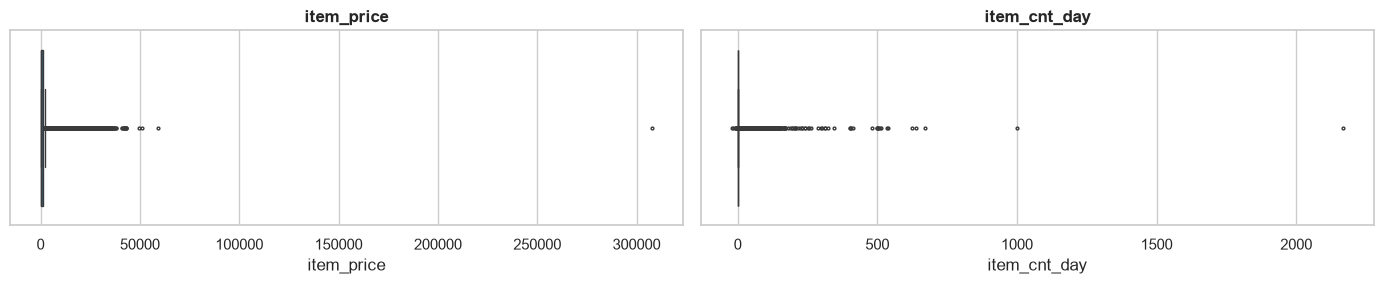

In [11]:
invalidos = pd.Series({
    "item_price <= 0": (ventas["item_price"] <= 0).sum(),
    "item_price > 100,000": (ventas["item_price"] > 100_000).sum(),
    "item_cnt_day < 0 (devoluciones)": (ventas["item_cnt_day"] < 0).sum(),
    "item_cnt_day == 0": (ventas["item_cnt_day"] == 0).sum(),
    "item_cnt_day no entero": (ventas["item_cnt_day"] % 1 != 0).sum(),
    "item_cnt_day > 1,000": (ventas["item_cnt_day"] > 1_000).sum(),
}, name="filas").to_frame()
invalidos["porcentaje"] = invalidos["filas"] / len(ventas) * 100
display(invalidos)

print("Precio <= 0:")
display(ventas[ventas["item_price"] <= 0])
print("Cinco precios más altos:")
display(ventas.nlargest(5, "item_price"))
print("Cinco cantidades diarias más altas:")
display(ventas.nlargest(5, "item_cnt_day"))

fig, ejes = plt.subplots(1, 2, figsize=(14, 3))
sns.boxplot(x=ventas["item_price"], ax=ejes[0], color=COLOR,
            flierprops={"markersize": 2})
ejes[0].set_title("item_price")
sns.boxplot(x=ventas["item_cnt_day"], ax=ejes[1], color=COLOR,
            flierprops={"markersize": 2})
ejes[1].set_title("item_cnt_day")
plt.tight_layout()
plt.show()

**Devoluciones:** filas con `item_cnt_day < 0`, por año y por tienda.

In [12]:
devoluciones = ventas[ventas["item_cnt_day"] < 0]
print(f"Unidades devueltas: {-devoluciones['item_cnt_day'].sum():,.0f} "
      f"({-devoluciones['item_cnt_day'].sum() / ventas.loc[ventas['item_cnt_day'] > 0, 'item_cnt_day'].sum():.2%} "
      "de las unidades vendidas)")
print("Valores de item_cnt_day en devoluciones:",
      devoluciones["item_cnt_day"].value_counts().head(5).to_dict())
display(devoluciones.groupby(devoluciones["date"].dt.year)
        .size().rename("filas_devolucion").to_frame().T)

Unidades devueltas: 7,541 (0.21% de las unidades vendidas)
Valores de item_cnt_day en devoluciones: {-1.0: 7252, -2.0: 78, -3.0: 14, -5.0: 4, -4.0: 3}


date,2013,2014,2015
filas_devolucion,3071,2650,1635


### 4.3 Registros duplicados en las ventas

- **Duplicados exactos:** las seis columnas iguales.
- **Duplicados parciales:** la misma fecha, tienda y producto, pero con otro precio o cantidad.

In [13]:
clave_dia = ["date", "shop_id", "item_id"]
n_exactos = ventas.duplicated().sum()
n_parciales = ventas.duplicated(clave_dia).sum() - n_exactos
print(f"Duplicados exactos (filas sobrantes): {n_exactos}")
print(f"Duplicados parciales (misma fecha-tienda-producto): {n_parciales}")

print("Duplicados exactos:")
display(ventas[ventas.duplicated(keep=False)].sort_values(clave_dia))
parciales = ventas[ventas.duplicated(clave_dia, keep=False)
                   & ~ventas.duplicated(keep=False)]
print("Ejemplo de duplicados parciales:")
display(parciales.sort_values(clave_dia).head(8))

Duplicados exactos (filas sobrantes): 6
Duplicados parciales (misma fecha-tienda-producto): 22
Duplicados exactos:


,date,date_block_num,shop_id,item_id,item_price,item_cnt_day
76961,2013-01-05,0,54,20130,149.00,1.00
76962,2013-01-05,0,54,20130,149.00,1.00
1435365,2014-02-23,13,50,3423,999.00,1.00
1435367,2014-02-23,13,50,3423,999.00,1.00
1496765,2014-03-23,14,21,3423,999.00,1.00
1496766,2014-03-23,14,21,3423,999.00,1.00
1671872,2014-05-01,16,50,3423,999.00,1.00
1671873,2014-05-01,16,50,3423,999.00,1.00
1866322,2014-07-12,18,25,3423,999.00,1.00
1866340,2014-07-12,18,25,3423,999.00,1.00


Ejemplo de duplicados parciales:


,date,date_block_num,shop_id,item_id,item_price,item_cnt_day
70686,2013-01-25,0,31,14050,349.00,1.00
70718,2013-01-25,0,31,14050,248.00,1.00
103461,2013-01-27,0,38,15702,549.00,1.00
103463,2013-01-27,0,38,15702,149.00,-1.00
6959,2013-01-29,0,25,12133,889.00,1.00
6960,2013-01-29,0,25,12133,"1,389.00",1.00
210156,2013-02-16,1,25,12133,"1,389.00",1.00
210173,2013-02-16,1,25,12133,889.00,1.00


### 4.4 Duplicados en los catálogos y tiendas repetidas

Se verifica que los IDs sean únicos y se buscan tiendas con el mismo nombre normalizado: en minúsculas, sin signos y sin la marca `фран` (franquicia). Después se compara en qué meses vende cada una.

In [14]:
for nombre, df, col in [("items", items, "item_id"),
                        ("item_categories", categorias,
                         "item_category_id"),
                        ("shops", tiendas, "shop_id")]:
    print(f"{nombre:<16} IDs repetidos: {df[col].duplicated().sum()} "
          f"| filas repetidas: {df.duplicated().sum()}")
print("items con el mismo nombre y distinto ID:",
      items["item_name"].duplicated().sum())


def normalizar_tienda(nombre: str) -> str:
    """Minúsculas, sin 'фран' ni signos, espacios simples."""
    texto = nombre.lower().replace("фран", "")
    texto = re.sub(r"[^0-9a-zа-яё ]", "", texto)
    return re.sub(r"\s+", " ", texto).strip()


tiendas_norm = tiendas.assign(
    nombre_normalizado=tiendas["shop_name"].map(normalizar_tienda))
repetidas = tiendas_norm[
    tiendas_norm["nombre_normalizado"].duplicated(keep=False)]
print("Tiendas con el mismo nombre normalizado:")
display(repetidas.merge(tiendas_es[["shop_id", "shop_name_es"]]))

PARES_SOSPECHOSOS = [(0, 57), (1, 58), (10, 11), (39, 40)]
actividad = ventas.groupby("shop_id")["date_block_num"].agg(
    primer_mes="min", ultimo_mes="max", meses_con_venta="nunique")
actividad["en_test"] = actividad.index.isin(test["shop_id"].unique())
filas = []
for a, b in PARES_SOSPECHOSOS:
    meses_a = set(ventas.loc[ventas["shop_id"] == a, "date_block_num"])
    meses_b = set(ventas.loc[ventas["shop_id"] == b, "date_block_num"])
    for tienda in (a, b):
        filas.append({"par": f"{a}-{b}", "shop_id": tienda,
                      **actividad.loc[tienda].to_dict(),
                      "meses_en_comun": len(meses_a & meses_b)})
display(pd.DataFrame(filas).merge(tiendas_es[["shop_id", "shop_name_es"]]))

items            IDs repetidos: 0 | filas repetidas: 0
item_categories  IDs repetidos: 0 | filas repetidas: 0
shops            IDs repetidos: 0 | filas repetidas: 0
items con el mismo nombre y distinto ID: 0
Tiendas con el mismo nombre normalizado:


,shop_name,shop_id,nombre_normalizado,shop_name_es
0,"!Якутск Орджоникидзе, 56 фран",0,якутск орджоникидзе 56,"Yakutsk, Ordzhonikidze 56 (franquicia)"
1,"!Якутск ТЦ ""Центральный"" фран",1,якутск тц центральный,"Yakutsk, CC ""Tsentralny"" (franquicia)"
2,Жуковский ул. Чкалова 39м?,10,жуковский ул чкалова 39м,"Zhukovski, calle Chkálova 39m? (texto corrupto)"
3,Жуковский ул. Чкалова 39м²,11,жуковский ул чкалова 39м,"Zhukovski, calle Chkálova 39m²"
4,"Якутск Орджоникидзе, 56",57,якутск орджоникидзе 56,"Yakutsk, Ordzhonikidze 56"
5,"Якутск ТЦ ""Центральный""",58,якутск тц центральный,"Yakutsk, CC ""Tsentralny"""


,par,shop_id,primer_mes,ultimo_mes,meses_con_venta,en_test,meses_en_comun,shop_name_es
0,0-57,0,0,1,2,False,0,"Yakutsk, Ordzhonikidze 56 (franquicia)"
1,0-57,57,2,33,32,True,0,"Yakutsk, Ordzhonikidze 56"
2,1-58,1,0,1,2,False,0,"Yakutsk, CC ""Tsentralny"" (franquicia)"
3,1-58,58,2,33,32,True,0,"Yakutsk, CC ""Tsentralny"""
4,10-11,10,0,33,33,True,0,"Zhukovski, calle Chkálova 39m? (texto corrupto)"
5,10-11,11,25,25,1,False,0,"Zhukovski, calle Chkálova 39m²"
6,39-40,39,14,33,20,True,11,"Rostov del Don, CCO ""Megatsentr Gorizont"""
7,39-40,40,14,24,11,False,11,"Rostov del Don, CCO ""Megatsentr Gorizont"" Ostr..."


### 4.5 Estrategia de limpieza (decisiones) y aplicación

| Problema | Filas | Decisión | Justificación |
|---|---|---|---|
| Nulos | 0 | Nada que imputar | Ninguna tabla tiene nulos. |
| Duplicados exactos | 6 | **Eliminar** | Son registros dobles de la misma transacción. |
| Duplicados parciales | 22 | Conservar | Pueden ser dos ventas reales del mismo producto a distinto precio en el día; al agregar al mes se suman. |
| Precio ≤ 0 | 1 | **Eliminar** | Precio de -1: error de captura. |
| Precio > 100,000 | 1 | **Eliminar** | Una sola venta de 307,980 en la tienda en línea, 5 veces mayor que el siguiente precio. |
| Cantidad > 1,000 | 1 | **Eliminar** | 2,169 unidades a 0.91 en la tienda en línea: venta atípica (mayorista o error). |
| Devoluciones (`item_cnt_day < 0`) | 7,356 | **Conservar y netear** | Al agregar al mes, la venta es neta, igual que el target de Kaggle. |
| Tiendas repetidas | 0→57, 1→58, 11→10 | **Unificar** al ID que aparece en test | Mismo nombre; sus meses de venta no se traslapan (una reemplaza a la otra). Las 39 y 40 venden en paralelo y se dejan separadas. |

La limpieza se aplica aquí **en memoria** para que el resto del análisis use datos consistentes. En la fase 2 se implementará como parte del pipeline. Además, se agregan el ingreso, los catálogos traducidos y las columnas de calendario.

In [15]:
MAPA_TIENDAS = {0: 57, 1: 58, 11: 10}
PRECIO_MAX, CANTIDAD_MAX = 100_000, 1_000

bitacora = [("Filas originales", len(ventas))]
ventas = ventas.drop_duplicates()
bitacora.append(("Sin duplicados exactos", len(ventas)))
ventas = ventas[(ventas["item_price"] > 0)
                & (ventas["item_price"] <= PRECIO_MAX)
                & (ventas["item_cnt_day"] <= CANTIDAD_MAX)]
bitacora.append(("Sin precios inválidos ni extremos", len(ventas)))
ventas = ventas.assign(shop_id=ventas["shop_id"].replace(MAPA_TIENDAS))
print("¿test usa algún ID unificado?",
      test["shop_id"].isin(MAPA_TIENDAS.keys()).any())

ventas["ingreso"] = ventas["item_price"] * ventas["item_cnt_day"]
ventas = (
    ventas
    .merge(items[["item_id", "item_category_id"]], on="item_id",
           how="left")
    .merge(categorias_es[["item_category_id", "item_category_name_es",
                          "categoria_principal", "es_digital"]],
           on="item_category_id", how="left")
    .merge(tiendas_es[["shop_id", "shop_name_es", "ciudad",
                       "tipo_tienda"]], on="shop_id", how="left")
)
ventas["anio"] = ventas["date"].dt.year
ventas["mes"] = ventas["date"].dt.month
ventas["dia_semana"] = ventas["date"].dt.day_of_week
ventas["semana"] = ventas["date"].dt.to_period("W").dt.start_time
bitacora.append(("Final (con catálogos)", len(ventas)))

display(pd.DataFrame(bitacora, columns=["paso", "filas"]))
print("Nulos tras los merges:", ventas.isna().sum().sum())
print("Tiendas distintas:", ventas["shop_id"].nunique())
ventas.head()

¿test usa algún ID unificado? False


,paso,filas
0,Filas originales,2935849
1,Sin duplicados exactos,2935843
2,Sin precios inválidos ni extremos,2935840
3,Final (con catálogos),2935840


Nulos tras los merges: 0
Tiendas distintas: 57


,date,date_block_num,shop_id,item_id,item_price,item_cnt_day,ingreso,item_category_id,item_category_name_es,categoria_principal,es_digital,shop_name_es,ciudad,tipo_tienda,anio,mes,dia_semana,semana
0,2013-01-02,0,59,22154,999.00,1.00,999.00,37,Cine - Blu-Ray,Cine,0,"Yaroslavl, CC ""Altair""",Yaroslavl,Centro comercial,2013,1,2,2012-12-31
1,2013-01-03,0,25,2552,899.00,1.00,899.00,58,Música - Vinilo,Música,0,"Moscú, CCO ""Atrium""",Moscú,Centro comercial y de ocio,2013,1,3,2012-12-31
2,2013-01-05,0,25,2552,899.00,-1.00,-899.00,58,Música - Vinilo,Música,0,"Moscú, CCO ""Atrium""",Moscú,Centro comercial y de ocio,2013,1,5,2012-12-31
3,2013-01-06,0,25,2554,"1,709.05",1.00,"1,709.05",58,Música - Vinilo,Música,0,"Moscú, CCO ""Atrium""",Moscú,Centro comercial y de ocio,2013,1,6,2012-12-31
4,2013-01-15,0,25,2555,"1,099.00",1.00,"1,099.00",56,Música - CD de producción de sello,Música,0,"Moscú, CCO ""Atrium""",Moscú,Centro comercial y de ocio,2013,1,1,2013-01-14


## 5. Análisis descriptivo general

### 5.1 Métricas básicas de precio, cantidad e ingreso

Media, mediana, mínimo, máximo y desviación estándar por transacción diaria (`ingreso` en rublos).

,mean,median,min,max,std,sesgo
item_price,890.75,399.00,0.07,"59,200.00","1,720.49",8.99
item_cnt_day,1.24,1.00,-22.00,"1,000.00",2.29,118.66
ingreso,"1,157.63",449.00,"-68,970.00","1,829,990.00","5,680.79",103.66


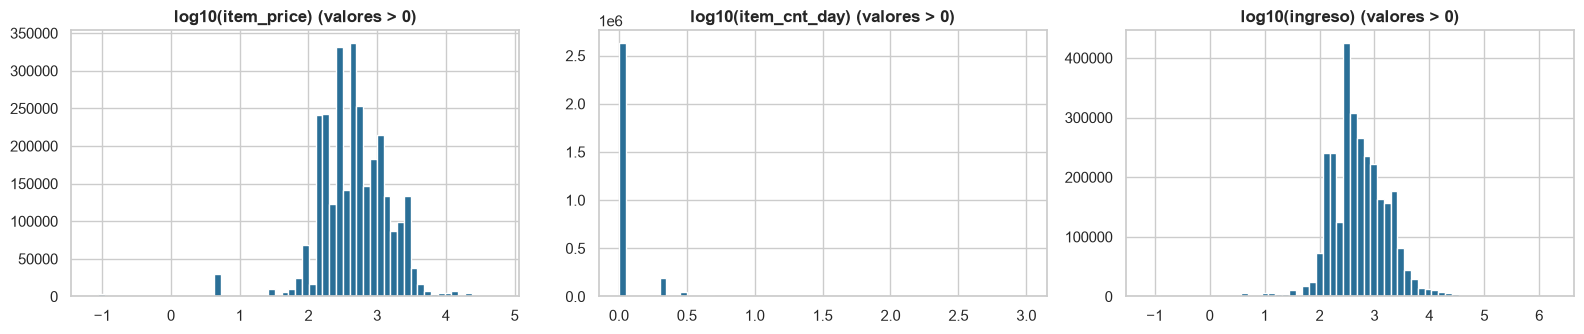

In [16]:
VARS = ["item_price", "item_cnt_day", "ingreso"]
resumen = ventas[VARS].agg(["mean", "median", "min", "max", "std"]).T
resumen["sesgo"] = ventas[VARS].skew()
display(resumen)

fig, ejes = plt.subplots(1, 3, figsize=(16, 3.5))
for eje, var in zip(ejes, VARS):
    valores = ventas.loc[ventas[var] > 0, var]
    eje.hist(np.log10(valores), bins=60, color=COLOR)
    eje.set_title(f"log10({var}) (valores > 0)")
plt.tight_layout()
plt.show()

### 5.2 Ventas por producto y por categoría

Unidades netas e ingreso por producto, con la concentración de las ventas (curva de Pareto), y por categoría principal y subcategoría.

Productos del catálogo: 22,170 | con ventas: 21,806 | sin ninguna venta: 364


,count,mean,std,min,25%,50%,75%,90%,99%,max
unidades,"21,806.00",167.20,"1,365.86",-11.00,7.00,33.00,124.00,360.00,"1,991.80","187,642.00"
ingreso,"21,806.00","155,856.73","1,696,731.10","-28,589.00","2,394.25","12,760.50","54,886.52","214,116.29","2,560,305.62","219,391,488.92"
meses_con_venta,"21,806.00",10.73,8.65,1.00,3.00,9.00,16.00,23.00,34.00,34.00


El 1% de los productos más vendidos aporta 28.1% de las unidades
El 10% de los productos más vendidos aporta 67.6% de las unidades
El 20% de los productos más vendidos aporta 82.4% de las unidades


,unidades,ingreso,productos,%_unidades,%_ingreso,precio_medio
categoria_principal,,,,,,
Juegos,"1,335,989.00","1,631,848,102.10",3871,36.64,48.02,"1,221.45"
Cine,"916,941.00","334,987,320.19",7390,25.15,9.86,365.33
Regalos,"584,366.00","309,146,571.48",3461,16.03,9.10,529.03
Música,"411,294.00","149,719,998.79",4259,11.28,4.41,364.02
Accesorios,"85,056.00","166,386,781.45",217,2.33,4.90,"1,956.20"
Libros,"76,341.00","30,348,897.24",1229,2.09,0.89,397.54
Programas,"74,953.00","122,082,915.13",1133,2.06,3.59,"1,628.79"
Tarjetas de pago,"53,883.00","72,953,095.72",41,1.48,2.15,"1,353.92"
Consolas de videojuegos,"32,155.00","528,028,109.44",144,0.88,15.54,"16,421.34"


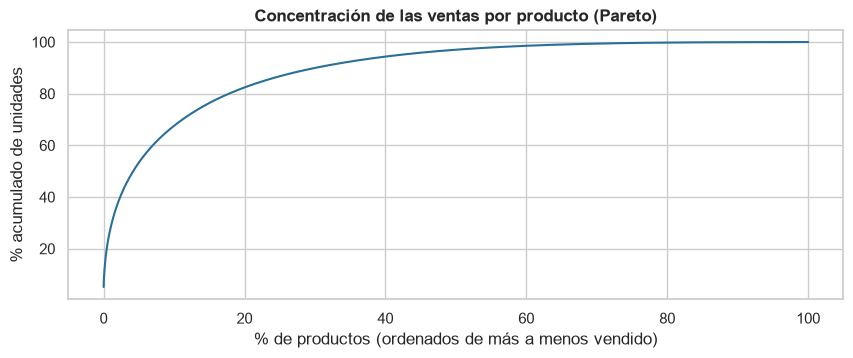

In [17]:
por_item = ventas.groupby("item_id").agg(
    unidades=("item_cnt_day", "sum"),
    ingreso=("ingreso", "sum"),
    meses_con_venta=("date_block_num", "nunique"),
)
print(f"Productos del catálogo: {len(items):,} | con ventas: "
      f"{len(por_item):,} | sin ninguna venta: "
      f"{len(items) - len(por_item):,}")
display(por_item.describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.99]).T)

acumulado = (por_item["unidades"].sort_values(ascending=False).cumsum()
             / por_item["unidades"].sum())
for p in (0.01, 0.1, 0.2):
    k = int(len(acumulado) * p)
    print(f"El {p:.0%} de los productos más vendidos aporta "
          f"{acumulado.iloc[k - 1]:.1%} de las unidades")

por_categoria = ventas.groupby("categoria_principal").agg(
    unidades=("item_cnt_day", "sum"),
    ingreso=("ingreso", "sum"),
    productos=("item_id", "nunique"),
).sort_values("unidades", ascending=False)
por_categoria["%_unidades"] = (por_categoria["unidades"]
                               / por_categoria["unidades"].sum() * 100)
por_categoria["%_ingreso"] = (por_categoria["ingreso"]
                              / por_categoria["ingreso"].sum() * 100)
por_categoria["precio_medio"] = (por_categoria["ingreso"]
                                 / por_categoria["unidades"])
display(por_categoria)

fig, eje = plt.subplots(figsize=(10, 3.5))
eje.plot(np.arange(1, len(acumulado) + 1) / len(acumulado) * 100,
         acumulado.values * 100, color=COLOR)
eje.set_xlabel("% de productos (ordenados de más a menos vendido)")
eje.set_ylabel("% acumulado de unidades")
eje.set_title("Concentración de las ventas por producto (Pareto)")
plt.show()

### 5.3 Ventas por sucursal

Totales por tienda, ciudad y tipo de tienda. `unidades_por_mes` divide entre los meses en que la tienda vendió, para no castigar a las tiendas que abrieron tarde o cerraron.

In [18]:
por_tienda = ventas.groupby(["shop_id", "shop_name_es"]).agg(
    unidades=("item_cnt_day", "sum"),
    ingreso=("ingreso", "sum"),
    meses_con_venta=("date_block_num", "nunique"),
    productos=("item_id", "nunique"),
).reset_index()
por_tienda["unidades_por_mes"] = (por_tienda["unidades"]
                                  / por_tienda["meses_con_venta"])
display(por_tienda[["unidades", "ingreso", "meses_con_venta",
                    "unidades_por_mes"]].describe().T)

for col in ("ciudad", "tipo_tienda"):
    agrupado = ventas.groupby(col).agg(
        tiendas=("shop_id", "nunique"),
        unidades=("item_cnt_day", "sum"),
        ingreso=("ingreso", "sum"),
    ).sort_values("unidades", ascending=False)
    agrupado["%_unidades"] = (agrupado["unidades"]
                              / agrupado["unidades"].sum() * 100)
    display(agrupado.head(10))

,count,mean,std,min,25%,50%,75%,max
unidades,57.00,"63,965.42","58,413.29",330.00,"25,838.00","53,886.00","71,201.00","310,777.00"
ingreso,57.00,"59,624,767.55","49,666,444.72","377,714.00","27,714,110.02","49,792,061.50","70,204,774.88","235,217,019.05"
meses_con_venta,57.00,27.82,10.36,1.00,25.00,34.00,34.00,34.00
unidades_por_mes,57.00,"2,166.84","1,672.47",330.00,"1,292.41","1,879.00","2,242.24","9,140.50"


,tiendas,unidades,ingreso,%_unidades
ciudad,,,,
Moscú,13,"1,276,373.00","1,132,704,332.15",35.01
Yakutsk,2,"240,857.00","191,612,978.36",6.61
San Petersburgo,2,"195,541.00","214,134,233.00",5.36
Jimki,1,"185,789.00","141,939,524.00",5.10
Vorónezh,3,"171,142.00","167,374,470.35",4.69
Tiumén,3,"142,093.00","122,294,684.25",3.90
En línea,2,"134,696.00","161,687,183.36",3.69
Ufá,2,"111,401.00","101,565,283.38",3.06
Krasnoyarsk,2,"91,324.00","111,177,649.29",2.50


,tiendas,unidades,ingreso,%_unidades
tipo_tienda,,,,
Centro comercial,32,"2,336,966.00","2,141,653,817.44",64.10
Centro comercial y de ocio,17,"814,003.00","774,222,552.74",22.33
Tienda de calle,4,"338,626.00","298,075,436.03",9.29
En línea,2,"134,696.00","161,687,183.36",3.69
Itinerante,1,"15,866.00","16,372,837.00",0.44
Liquidación,1,"5,872.00","6,599,924.00",0.16


### 5.4 Ventas por periodo de tiempo

Distribución de las unidades vendidas por día, semana, mes y año. Como 2015 solo llega hasta octubre, los años se comparan también con enero a octubre.

In [19]:
diaria = ventas.groupby("date")["item_cnt_day"].sum()
semanal = ventas.groupby("semana")["item_cnt_day"].sum().iloc[1:-1]
mensual_total = ventas.groupby("date_block_num")["item_cnt_day"].sum()
periodos = pd.DataFrame({
    "diaria": diaria.describe(),
    "semanal (completas)": semanal.describe(),
    "mensual": mensual_total.describe(),
}).T
display(periodos)

anual = ventas.groupby("anio").agg(
    unidades=("item_cnt_day", "sum"),
    ingreso=("ingreso", "sum"),
    meses=("mes", "nunique"),
)
ene_oct = ventas[ventas["mes"] <= 10].groupby("anio").agg(
    unidades_ene_oct=("item_cnt_day", "sum"),
    ingreso_ene_oct=("ingreso", "sum"),
)
anual = anual.join(ene_oct)
anual["var_unidades_ene_oct_%"] = (anual["unidades_ene_oct"]
                                   .pct_change() * 100)
anual["var_ingreso_ene_oct_%"] = anual["ingreso_ene_oct"].pct_change() * 100
anual

,count,mean,std,min,25%,50%,75%,max
diaria,"1,034.00","3,526.14","1,586.03","1,274.00","2,464.25","3,144.50","4,257.00","13,343.00"
semanal (completas),146.00,"24,645.95","7,801.23","12,389.00","19,959.25","24,500.50","27,672.50","57,680.00"
mensual,34.00,"107,236.15","28,541.88","63,187.00","85,968.25","107,306.00","125,358.50","183,341.00"


,unidades,ingreso,meses,unidades_ene_oct,ingreso_ene_oct,var_unidades_ene_oct_%,var_ingreso_ene_oct_%
anio,,,,,,,
2013,"1,562,730.00","1,217,216,605.98",12,"1,249,380.00","871,287,415.22",NaN,NaN
2014,"1,320,884.00","1,346,773,983.81",12,"1,034,285.00","962,711,712.66",-17.22,10.49
2015,"762,415.00","834,621,160.78",10,"762,415.00","834,621,160.78",-26.29,-13.31


**Hallazgos del análisis descriptivo**

- **Transacciones pequeñas:** la mediana de `item_cnt_day` es 1, y precio, cantidad e ingreso tienen un sesgo fuerte a la derecha (sesgo de 9, 119 y 104).
- **Ventas muy concentradas:** el 1 % de los productos aporta el 28 % de las unidades, y el 20 % aporta el 82 %. El producto más vendido (item 20949, la bolsa de la marca "1С Интерес") suma 187,642 unidades, diez veces más que el segundo. Es un artículo que acompaña a otras compras.
- **Categorías:** Juegos (37 % de las unidades y 48 % del ingreso), Cine (25 %) y Regalos (16 %) suman el 78 % de las unidades. Las consolas son solo el 0.9 % de las unidades, pero el 15.5 % del ingreso.
- **Geografía:** Moscú concentra el 35 % de las unidades con 13 tiendas; los centros comerciales, el 64 %.
- **Caída sostenida:** comparando enero a octubre, las unidades bajaron 17 % en 2014 y 26 % en 2015. El ingreso subió 10 % en 2014, probablemente por el mayor peso de productos caros como las consolas de nueva generación, y cayó 13 % en 2015.

## 6. Exploración temporal

### 6.1 Evolución de las ventas

Unidades diarias con una media móvil de 30 días, y unidades e ingreso mensuales.

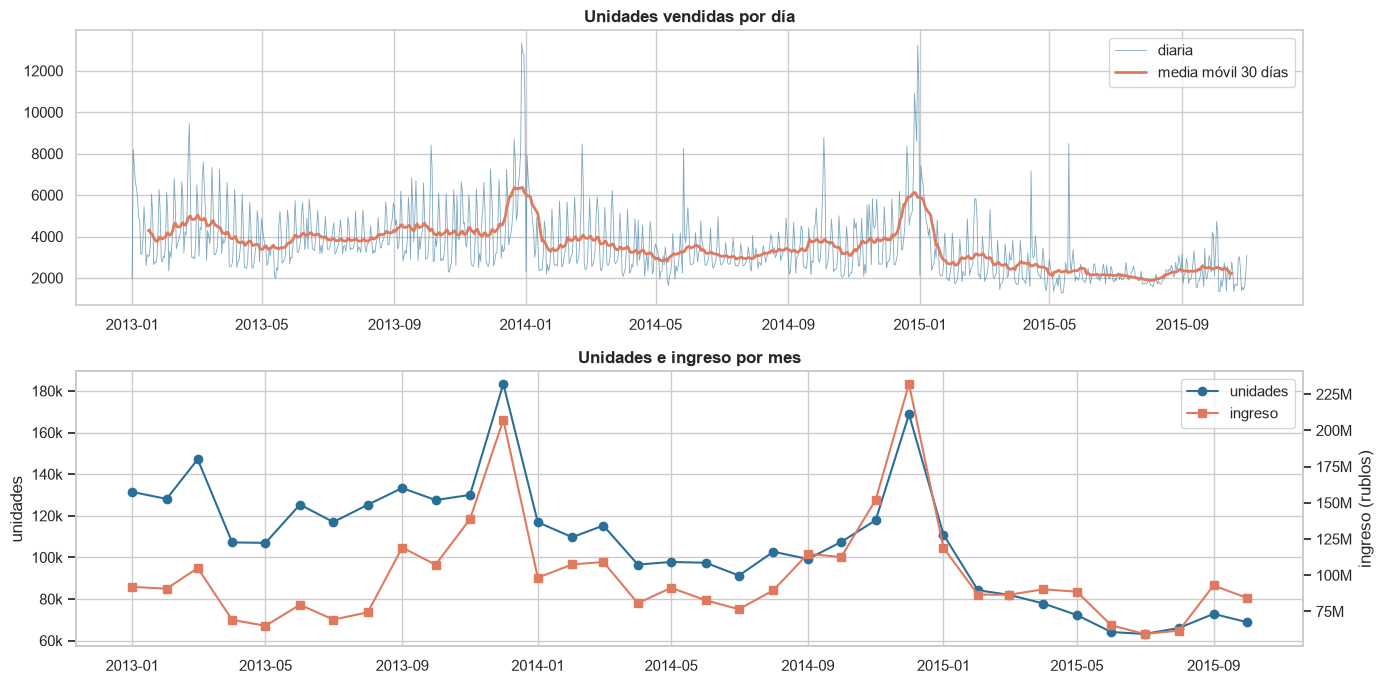

In [20]:
fig, ejes = plt.subplots(2, 1, figsize=(14, 7))
ejes[0].plot(diaria.index, diaria.values, color=COLOR, lw=0.6,
             alpha=0.6, label="diaria")
ejes[0].plot(diaria.index, diaria.rolling(30, center=True).mean(),
             color=COLOR_ALT, lw=2, label="media móvil 30 días")
ejes[0].set_title("Unidades vendidas por día")
ejes[0].legend()

meses_fecha = pd.date_range("2013-01-01", periods=34, freq="MS")
ingreso_mensual = ventas.groupby("date_block_num")["ingreso"].sum()
ejes[1].plot(meses_fecha, mensual_total.values, marker="o", color=COLOR,
             label="unidades")
ejes[1].yaxis.set_major_formatter(MILES)
ejes[1].set_ylabel("unidades")
eje_ingreso = ejes[1].twinx()
eje_ingreso.plot(meses_fecha, ingreso_mensual.values, marker="s",
                 color=COLOR_ALT, label="ingreso")
eje_ingreso.yaxis.set_major_formatter(MILLONES)
eje_ingreso.set_ylabel("ingreso (rublos)")
eje_ingreso.grid(False)
ejes[1].set_title("Unidades e ingreso por mes")
lineas = ejes[1].get_lines() + eje_ingreso.get_lines()
ejes[1].legend(lineas, [linea.get_label() for linea in lineas],
               loc="upper right")
plt.tight_layout()
plt.show()

### 6.2 Tendencia y estacionalidad

Descomposición aditiva de la serie mensual de unidades (periodo de 12 meses), comparación año contra año y prueba de Dickey-Fuller aumentada (ADF) de estacionariedad.

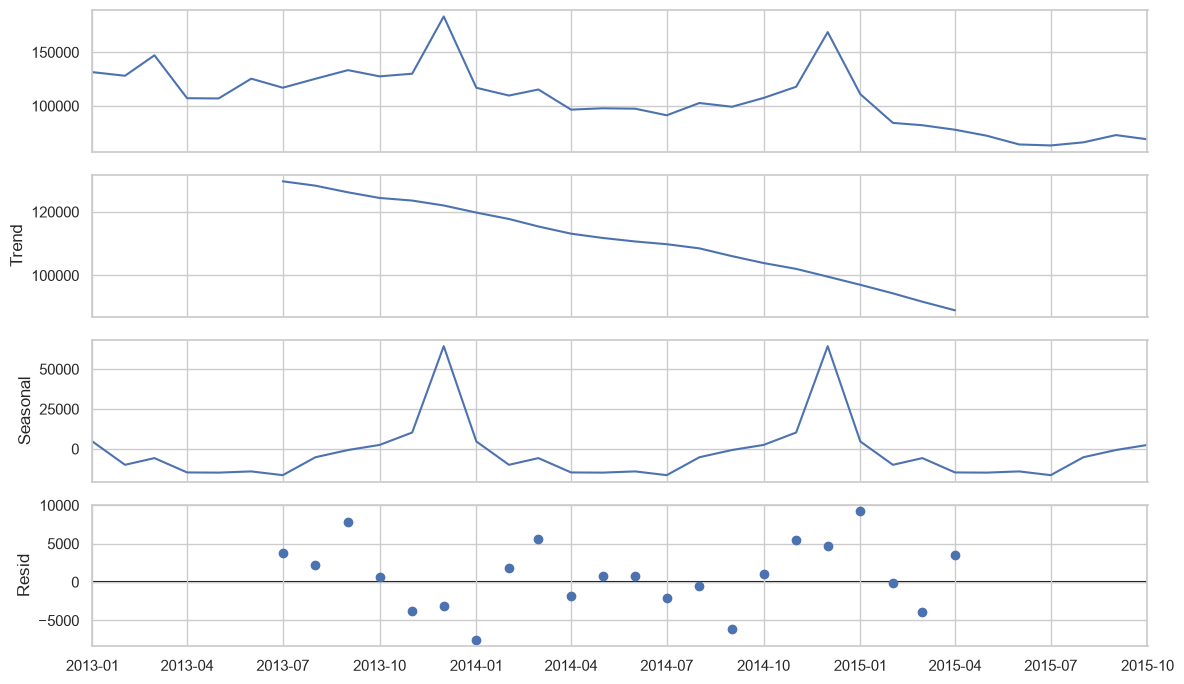

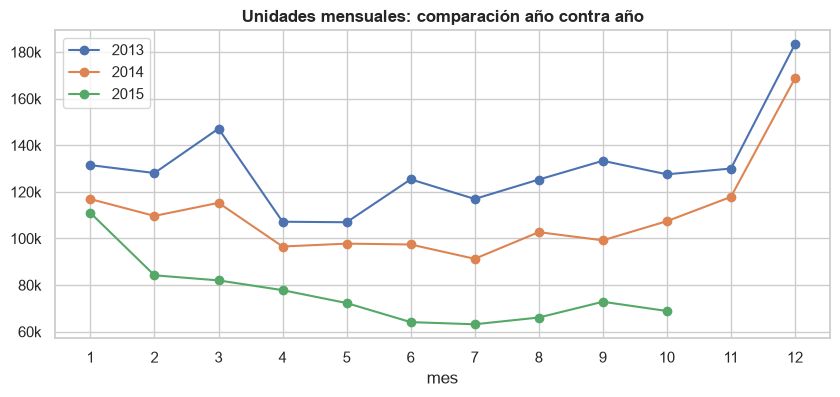

ADF serie mensual: estadístico=-2.369, p-valor=0.151
ADF primera diferencia: estadístico=-13.170, p-valor=0.000


In [21]:
serie_mensual = pd.Series(mensual_total.values, index=meses_fecha)
descomposicion = seasonal_decompose(serie_mensual, model="additive",
                                    period=12)
fig = descomposicion.plot()
fig.set_size_inches(12, 7)
plt.tight_layout()
plt.show()

fig, eje = plt.subplots(figsize=(10, 4))
por_anio_mes = ventas.groupby(["anio", "mes"])["item_cnt_day"].sum()
for anio, serie in por_anio_mes.groupby(level=0):
    eje.plot(serie.index.get_level_values(1), serie.values, marker="o",
             label=str(anio))
eje.set_xticks(range(1, 13))
eje.yaxis.set_major_formatter(MILES)
eje.set_xlabel("mes")
eje.set_title("Unidades mensuales: comparación año contra año")
eje.legend()
plt.show()

estadistico, p_valor, *_ = adfuller(serie_mensual, autolag="AIC",
                                    result_object=False)
print(f"ADF serie mensual: estadístico={estadistico:.3f}, "
      f"p-valor={p_valor:.3f}")
estadistico, p_valor, *_ = adfuller(serie_mensual.diff().dropna(),
                                    autolag="AIC", result_object=False)
print(f"ADF primera diferencia: estadístico={estadistico:.3f}, "
      f"p-valor={p_valor:.3f}")

### 6.3 Picos y caídas abruptas

Los días con más ventas y las mayores variaciones de un mes al siguiente.

In [22]:
print("Diez días con más unidades vendidas:")
display(diaria.nlargest(10).rename("unidades").to_frame().assign(
    dia_semana=lambda d: d.index.day_name()))

variacion = (serie_mensual.pct_change() * 100).rename("variacion_%")
extremos = pd.concat([variacion.nlargest(4), variacion.nsmallest(4)])
extremos.to_frame().assign(
    unidades=serie_mensual.loc[extremos.index].values)

Diez días con más unidades vendidas:


,unidades,dia_semana
date,,
2013-12-28,"13,343.00",Saturday
2014-12-30,"13,236.00",Tuesday
2013-12-29,"12,863.00",Sunday
2013-12-30,"12,823.00",Monday
2014-12-31,"11,393.00",Wednesday
2014-12-27,"10,919.00",Saturday
2013-12-31,"10,514.00",Tuesday
2014-12-28,"9,727.00",Sunday
2013-02-23,"9,456.00",Saturday


,variacion_%,unidades
2014-12-01,43.20,"168,754.00"
2013-12-01,41.02,"183,341.00"
2013-06-01,17.21,"125,381.00"
2013-03-01,14.87,"147,142.00"
2014-01-01,-36.24,"116,899.00"
2015-01-01,-34.24,"110,971.00"
2013-04-01,-27.15,"107,190.00"
2015-02-01,-24.13,"84,198.00"


### 6.4 Ciclos por día de la semana y por mes del año

Promedio de unidades diarias por día de la semana, y promedio mensual por mes del calendario (los meses 11 y 12 solo tienen datos de 2013 y 2014).

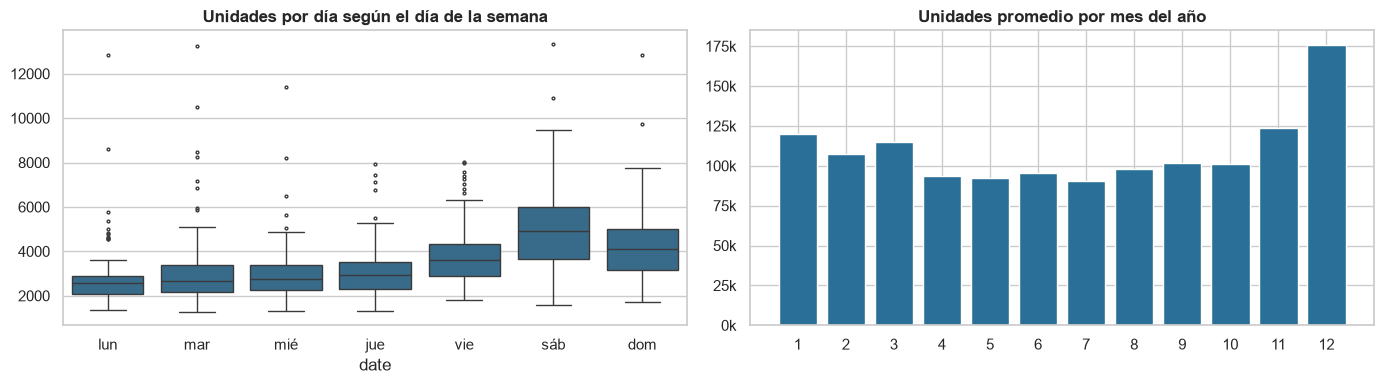

Índice por día de la semana (1 = promedio):
{'lun': 0.77, 'mar': 0.87, 'mié': 0.84, 'jue': 0.87, 'vie': 1.06, 'sáb': 1.41, 'dom': 1.18}
Índice por mes del año (1 = promedio):
{1: 1.12, 2: 1.0, 3: 1.07, 4: 0.88, 5: 0.86, 6: 0.89, 7: 0.84, 8: 0.91, 9: 0.95, 10: 0.94, 11: 1.16, 12: 1.64}


In [23]:
DIAS = ["lun", "mar", "mié", "jue", "vie", "sáb", "dom"]
por_dia = diaria.groupby(diaria.index.day_of_week)
fig, ejes = plt.subplots(1, 2, figsize=(14, 4))
sns.boxplot(x=diaria.index.day_of_week, y=diaria.values, ax=ejes[0],
            color=COLOR, flierprops={"markersize": 2})
ejes[0].set_xticks(range(7), DIAS)
ejes[0].set_title("Unidades por día según el día de la semana")
indice_dia = por_dia.mean() / diaria.mean()

por_mes = serie_mensual.groupby(serie_mensual.index.month).mean()
ejes[1].bar(por_mes.index, por_mes.values, color=COLOR)
ejes[1].set_xticks(range(1, 13))
ejes[1].yaxis.set_major_formatter(MILES)
ejes[1].set_title("Unidades promedio por mes del año")
plt.tight_layout()
plt.show()

print("Índice por día de la semana (1 = promedio):")
print(pd.Series(indice_dia.values, index=DIAS).round(2).to_dict())
print("Índice por mes del año (1 = promedio):")
print((por_mes / serie_mensual.mean()).round(2).to_dict())

**Hallazgos de la exploración temporal**

- **Tendencia decreciente:** la componente de tendencia baja de ~130 mil a ~88 mil unidades por mes entre mediados de 2013 y la primavera de 2015. La prueba ADF no rechaza la raíz unitaria en la serie mensual (p = 0.15), pero sí en su primera diferencia (p < 0.001): la serie **no es estacionaria en nivel**.
- **Estacionalidad anual:** diciembre es el pico (índice 1.64, es decir, 64 % por encima del mes promedio). Enero cae fuerte (-36 % en 2014 y -34 % en 2015 frente a diciembre), y abril a agosto son los meses más bajos. **Noviembre vendió 2 % y 10 % más que octubre en 2013 y 2014**, una referencia directa para el mes que se debe predecir.
- **Ciclo semanal:** el sábado vende 41 % más que el día promedio y el domingo 18 % más; el lunes es el día más débil (-23 %).
- **Picos:** los 8 días con más ventas caen entre el 27 y el 31 de diciembre. Fuera de diciembre destacan el 23 de febrero de 2013 (Día del Defensor de la Patria, fecha de regalos en Rusia) y el sábado 4 de octubre de 2014.

## 7. Análisis comparativo entre sucursales y productos

### 7.1 Productos y categorías más y menos vendidos

Por unidades netas. Entre los productos con menos ventas hay muchos empates, así que se resume cuántos venden muy poco.

In [24]:
nombres = items.set_index("item_id")["item_name"].str.slice(0, 55)
ranking = por_item.join(nombres).join(
    items.set_index("item_id")["item_category_id"]
    .map(categorias_es.set_index("item_category_id")
         ["item_category_name_es"]).rename("categoria"))
print("Diez productos más vendidos:")
display(ranking.nlargest(10, "unidades"))
print("Diez productos con más ingreso:")
display(ranking.nlargest(10, "ingreso"))
print("Productos con menos ventas:")
for umbral in (0, 1, 5):
    print(f"  unidades netas <= {umbral}: "
          f"{(ranking['unidades'] <= umbral).sum():,}")

por_subcategoria = ventas.groupby("item_category_name_es").agg(
    unidades=("item_cnt_day", "sum"), ingreso=("ingreso", "sum"),
).sort_values("unidades", ascending=False)
print("Categorías con más y menos unidades:")
display(pd.concat([por_subcategoria.head(8), por_subcategoria.tail(8)]))

Diez productos más vendidos:


,unidades,ingreso,meses_con_venta,item_name,categoria
item_id,,,,,
20949,"187,642.00","928,863.70",31,Фирменный пакет майка 1С Интерес белый (34*42)...,"Regalos - Bolsas, álbumes, mouse pads"
2808,"17,245.00","16,852,778.42",34,"Diablo III [PC, Jewel, русская версия]",Juegos - PC - Ediciones estándar
3732,"16,642.00","43,617,975.48",26,"Grand Theft Auto V [PS3, русские субтитры]",Juegos - PS3
17717,"15,830.00","17,200,825.93",34,Прием денежных средств для 1С-Онлайн,Servicio
5822,"14,515.00","15,408,983.12",34,Playstation Store пополнение бумажника: Карта ...,Tarjetas de pago - PSN
3734,"11,688.00","31,065,160.27",26,"Grand Theft Auto V [Xbox 360, русские субтитры]",Juegos - XBOX 360
6675,"10,289.00","219,391,488.92",24,Sony PlayStation 4 (500 Gb) Black (CUH-1008A/1...,Consolas de videojuegos - PS4
3731,"10,099.00","19,983,482.89",7,"Grand Theft Auto V [PC, русские субтитры]",Juegos - PC - Ediciones estándar
1855,"10,032.00","9,357,024.78",24,"Battlefield 4 [PC, русская версия]",Juegos - PC - Ediciones estándar


Diez productos con más ingreso:


,unidades,ingreso,meses_con_venta,item_name,categoria
item_id,,,,,
6675,"10,289.00","219,391,488.92",24,Sony PlayStation 4 (500 Gb) Black (CUH-1008A/1...,Consolas de videojuegos - PS4
3732,"16,642.00","43,617,975.48",26,"Grand Theft Auto V [PS3, русские субтитры]",Juegos - PS3
13443,"1,366.00","34,331,245.28",9,Комплект Sony PS4 (500 Gb) Black (CUH-1108A/B0...,Consolas de videojuegos - PS4
3734,"11,688.00","31,065,160.27",26,"Grand Theft Auto V [Xbox 360, русские субтитры]",Juegos - XBOX 360
3733,"6,506.00","22,298,864.36",12,"Grand Theft Auto V [PS4, русские субтитры]",Juegos - PS4
16787,"9,227.00","21,907,839.08",29,"Одни из нас [PS3, русская версия]",Juegos - PS3
3731,"10,099.00","19,983,482.89",7,"Grand Theft Auto V [PC, русские субтитры]",Juegos - PC - Ediciones estándar
13405,991.00,"18,125,479.52",14,"Комплект ""Microsoft Xbox One 500GB (Day One Ed...",Consolas de videojuegos - XBOX ONE
17717,"15,830.00","17,200,825.93",34,Прием денежных средств для 1С-Онлайн,Servicio


Productos con menos ventas:
  unidades netas <= 0: 8
  unidades netas <= 1: 2,326
  unidades netas <= 5: 5,014
Categorías con más y menos unidades:


,unidades,ingreso
item_category_name_es,,
Cine - DVD,"634,170.00","169,944,072.69"
Juegos - PC - Ediciones estándar,"456,540.00","257,519,291.08"
Música - CD de producción local,"348,591.00","100,022,563.57"
Juegos - PS3,"254,886.00","412,050,281.90"
Cine - Blu-Ray,"203,283.00","90,478,232.84"
"Regalos - Bolsas, álbumes, mouse pads","187,998.00","934,206.61"
Juegos - PC - Ediciones adicionales,"174,954.00","136,419,148.64"
Juegos - XBOX 360,"169,940.00","259,615,132.35"
Libros - Literatura de computación,6.00,"1,654.00"


### 7.2 Desempeño entre sucursales

Ranking de tiendas, tiendas que abrieron o cerraron dentro del periodo y tendencia reciente (unidades de 2015 frente a las de 2014 en enero a octubre).

In [25]:
tienda_anio = (ventas[ventas["mes"] <= 10]
               .pivot_table(index="shop_id", columns="anio",
                            values="item_cnt_day", aggfunc="sum"))
desempeno = por_tienda.set_index("shop_id").join(actividad[
    ["primer_mes", "ultimo_mes", "en_test"]])
# Los IDs unificados toman la actividad recalculada.
recalculada = ventas.groupby("shop_id")["date_block_num"].agg(["min",
                                                               "max"])
desempeno["primer_mes"] = recalculada["min"]
desempeno["ultimo_mes"] = recalculada["max"]
desempeno["var_2015_vs_2014_%"] = (tienda_anio[2015] / tienda_anio[2014]
                                   - 1) * 100
desempeno = desempeno.sort_values("unidades", ascending=False)
display(desempeno.head(10))
display(desempeno.tail(10))

print("Tiendas que abrieron después del mes 0:",
      desempeno.index[desempeno["primer_mes"] > 0].tolist())
print("Tiendas sin ventas en octubre 2015 (mes 33):",
      desempeno.index[desempeno["ultimo_mes"] < 33].tolist())
print("Tiendas especiales: 9 = itinerante, 12 y 55 = en línea, "
      "20 = liquidación")
de_test = desempeno[desempeno["en_test"]]["var_2015_vs_2014_%"].dropna()
print(f"Tiendas de test que vendieron menos en ene-oct 2015 que en "
      f"ene-oct 2014: {(de_test < 0).sum()} de {len(de_test)} "
      f"(mediana {de_test.median():.1f} %)")

,shop_name_es,unidades,ingreso,meses_con_venta,productos,unidades_por_mes,primer_mes,ultimo_mes,en_test,var_2015_vs_2014_%
shop_id,,,,,,,,,,
31,"Moscú, CC ""Semiónovski""","310,777.00","235,217,019.05",34,14416,"9,140.50",0,33,True,-21.47
25,"Moscú, CCO ""Atrium""","241,919.00","216,479,572.44",34,15367,"7,115.26",0,33,True,-9.84
54,"Jimki, CC ""Mega""","185,789.00","141,939,524.00",28,13863,"6,635.32",0,27,False,-73.86
28,"Moscú, CC ""MEGA Tyoply Stan"" II","184,557.00","159,746,337.38",34,12572,"5,428.15",0,33,True,-24.48
57,"Yakutsk, Ordzhonikidze 56","152,812.00","119,637,153.53",34,12815,"4,494.47",0,33,True,-33.44
42,"San Petersburgo, CC ""Nevski Tsentr""","144,933.00","151,916,533.55",34,12034,"4,262.74",0,33,True,8.12
27,"Moscú, CC ""MEGA Belaya Dacha II""","136,657.00","140,632,474.12",32,10842,"4,270.53",0,32,False,-39.45
6,"Vorónezh (Plejánovskaya, 13)","100,489.00","98,067,453.80",34,11856,"2,955.56",0,33,True,-34.17
58,"Yakutsk, CC ""Tsentralny""","88,045.00","71,975,824.83",34,9086,"2,589.56",0,33,True,-25.03


,shop_name_es,unidades,ingreso,meses_con_venta,productos,unidades_por_mes,primer_mes,ultimo_mes,en_test,var_2015_vs_2014_%
shop_id,,,,,,,,,,
39,"Rostov del Don, CCO ""Megatsentr Gorizont""","16,617.00","18,092,891.00",20,4096,830.85,14,33,True,37.63
9,Ventas itinerantes,"15,866.00","16,372,837.00",4,1404,"3,966.50",9,33,False,-48.25
32,"Moscú, CC ""Serebryany Dom""","8,780.00","5,772,825.00",7,3299,"1,254.29",0,6,False,NaN
23,"Moscú, CC ""Budenovski"" (pabellón A2)","7,705.00","5,621,521.20",4,2949,"1,926.25",0,3,False,NaN
34,"Nizhni Nóvgorod, CCO ""RIO""","6,451.00","8,582,822.01",16,1860,403.19,18,33,True,289.66
20,"Moscú ""Rasprodazha"" (liquidación)","5,872.00","6,599,924.00",2,746,"2,936.00",21,33,False,-19.93
33,"Mytishchi, CCO ""XL-3""","5,482.00","5,949,101.57",9,1900,609.11,19,27,False,75.73
40,"Rostov del Don, CCO ""Megatsentr Gorizont"" Ostr...","4,943.00","4,293,586.85",11,817,449.36,14,24,False,-85.04
8,"Vorónezh, CCO City-Park ""Grad""","3,595.00","2,349,358.00",4,1909,898.75,0,3,False,NaN


Tiendas que abrieron después del mes 0: [55, 5, 17, 48, 49, 39, 9, 34, 20, 33, 40, 36]
Tiendas sin ventas en octubre 2015 (mes 33): [54, 27, 30, 29, 43, 51, 17, 13, 32, 23, 33, 40, 8]
Tiendas especiales: 9 = itinerante, 12 y 55 = en línea, 20 = liquidación
Tiendas de test que vendieron menos en ene-oct 2015 que en ene-oct 2014: 34 de 41 (mediana -21.5 %)


### 7.3 Outliers y comportamientos anómalos

- **Ventas mensuales por par tienda-producto:** su distribución, cuántas superan 20 (el límite del recorte de Kaggle) y cuáles son los casos más altos.
- **Meses anómalos por tienda:** z-score de las unidades mensuales de cada tienda contra su propio promedio.
- **Precios anómalos por producto:** productos cuyo precio máximo es mucho mayor que su mediana.

In [26]:
claves = ["date_block_num", "shop_id", "item_id"]
mensual = (ventas.groupby(claves, as_index=False)["item_cnt_day"].sum()
           .rename(columns={"item_cnt_day": "item_cnt_month"}))
print(f"Pares tienda-producto-mes con al menos un registro: "
      f"{len(mensual):,}")
display(mensual["item_cnt_month"].describe(
    percentiles=[0.5, 0.9, 0.99, 0.999]).to_frame().T)
print(f"item_cnt_month > 20: {(mensual['item_cnt_month'] > 20).mean():.2%}"
      f" | < 0: {(mensual['item_cnt_month'] < 0).mean():.3%}")
print("Pares-mes con más unidades:")
display(mensual.nlargest(8, "item_cnt_month").merge(
    ranking[["item_name", "categoria"]], left_on="item_id",
    right_index=True))

tienda_mes = ventas.pivot_table(index="shop_id", columns="date_block_num",
                                values="item_cnt_day", aggfunc="sum")
z = tienda_mes.sub(tienda_mes.mean(axis=1), axis=0).div(
    tienda_mes.std(axis=1), axis=0)
anomalias = (z.stack().rename("z").reset_index()
             .query("abs(z) > 3").sort_values("z", ascending=False))
print("Meses de tienda con |z| > 3:")
display(anomalias.merge(tiendas_es[["shop_id", "shop_name_es"]]))

precio_item = ventas.groupby("item_id")["item_price"].agg(
    ["median", "max", "count"])
precio_item["max_sobre_mediana"] = precio_item["max"] / precio_item[
    "median"]
print("Productos con precio máximo > 10 veces su mediana:",
      (precio_item["max_sobre_mediana"] > 10).sum())
display(precio_item.nlargest(5, "max_sobre_mediana").join(nombres))

Pares tienda-producto-mes con al menos un registro: 1,609,123


,count,mean,std,min,50%,90%,99%,99.9%,max
item_cnt_month,"1,609,123.00",2.27,8.47,-22.00,1.00,4.00,17.00,74.00,"1,644.00"


item_cnt_month > 20: 0.71% | < 0: 0.057%
Pares-mes con más unidades:


,date_block_num,shop_id,item_id,item_cnt_month,item_name,categoria
1552019,32,12,9248,"1,644.00","Билет ""ИгроМир 2015"" - 3 октября 2015 (сайт) [...",Servicio - Boletos
1574409,32,55,9249,"1,644.00","Билет ""ИгроМир 2015"" - 3 октября 2015 (сайт) У...",Boletos - Digital
657942,11,31,20949,"1,305.00",Фирменный пакет майка 1С Интерес белый (34*42)...,"Regalos - Bolsas, álbumes, mouse pads"
1412963,27,55,3730,"1,242.00","Grand Theft Auto V [PC, Цифровая версия]",Juegos - PC - Digital
1226813,23,31,20949,"1,209.00",Фирменный пакет майка 1С Интерес белый (34*42)...,"Regalos - Bolsas, álbumes, mouse pads"
1297109,24,55,5917,"1,127.00","Prototype 2 [PC, Цифровая версия]",Juegos - PC - Digital
1574410,32,55,9251,"1,117.00","Билет ""ИгроМир 2015"" - 3 октября 2015 УПР [Циф...",Boletos - Digital
1145838,21,55,19437,"1,074.00","Средиземье: Тени Мордора [PC, Цифровая версия]",Juegos - PC - Digital


Meses de tienda con |z| > 3:


,shop_id,date_block_num,z,shop_name_es
0,2,23,4.22,"Adigea, CC ""Mega"""
1,21,23,3.92,"Moscú, CCO multifuncional ""Afi Mall"""
2,47,23,3.81,"Surgut, CCO ""City Mall"""
3,42,23,3.59,"San Petersburgo, CC ""Nevski Tsentr"""
4,39,23,3.42,"Rostov del Don, CCO ""Megatsentr Gorizont"""
5,38,11,3.30,"Omsk, CC ""Mega"""
6,58,11,3.28,"Yakutsk, CC ""Tsentralny"""
7,42,11,3.27,"San Petersburgo, CC ""Nevski Tsentr"""
8,21,11,3.24,"Moscú, CCO multifuncional ""Afi Mall"""
9,15,11,3.20,"Kaluga, CCO ""XXI vek"""


Productos con precio máximo > 10 veces su mediana: 39


,median,max,count,max_sobre_mediana,item_name
item_id,,,,,
11857,0.10,729.00,154,"7,290.00",Змей ВАСЯ антистресс 36 см.
11865,0.10,729.00,197,"7,290.00",Змей МАКС антистресс 33 см.
11869,0.10,510.30,113,"5,103.00",Змей ЯШКА антистресс 33 см.
11864,0.10,469.00,129,"4,690.00",Змей ДЖЕККИ с сердечком 36 см
11859,0.10,379.00,104,"3,790.00",Змей ВАСЯ с цветком 33 см


**Hallazgos del análisis comparativo**

- **Productos:** después de la bolsa 20949, los más vendidos son videojuegos de gran lanzamiento (Diablo III; GTA V en PS3, Xbox 360 y PC; Battlefield 4), las recargas de PlayStation Store y el servicio de cobro de 1C-Online. Por ingreso domina la consola PS4 (219 M de rublos). La cola es muy larga: 2,326 productos vendieron 1 unidad neta o menos en 34 meses, y 364 productos del catálogo nunca se vendieron.
- **Categorías:** las de mayor volumen son Cine - DVD, Juegos - PC estándar, Música - CD local y Juegos - PS3. Varias subcategorías de libros, accesorios y PS2 casi no tienen ventas.
- **Sucursales:** el desempeño es muy desigual. La tienda 31 (Moscú, Semiónovski) vende 9,140 unidades por mes; las más pequeñas, menos de 1,000. Además:
  - 12 tiendas abrieron después de enero 2013 y 13 no tienen ventas en octubre 2015 (ninguna de esas 13 está en test);
  - 34 de las 41 tiendas de test con datos comparables vendieron menos en 2015 que en 2014 (mediana: -21.5 %).
- **Outliers:**
  - El 0.71 % de los pares-mes supera 20 unidades. El máximo, 1,644, son boletos digitales de IgroMir 2015 en las tiendas en línea 12 y 55 (septiembre 2015).
  - Los meses anómalos de tienda (|z| > 3) se concentran en los diciembres (meses 11 y 23): es estacionalidad, no error.
  - Las tiendas en línea (12 y 55) concentran las cantidades extremas.
  - 39 productos tienen un precio máximo de más de 10 veces su mediana. Por ejemplo, unos peluches "antiestrés" con precio mediano de 0.10 rublos, probablemente regalos promocionales.

## 8. Visualizaciones clave

### 8.1 Serie de tiempo de ventas totales

Unidades netas mensuales e ingreso mensual, con los meses de diciembre marcados.

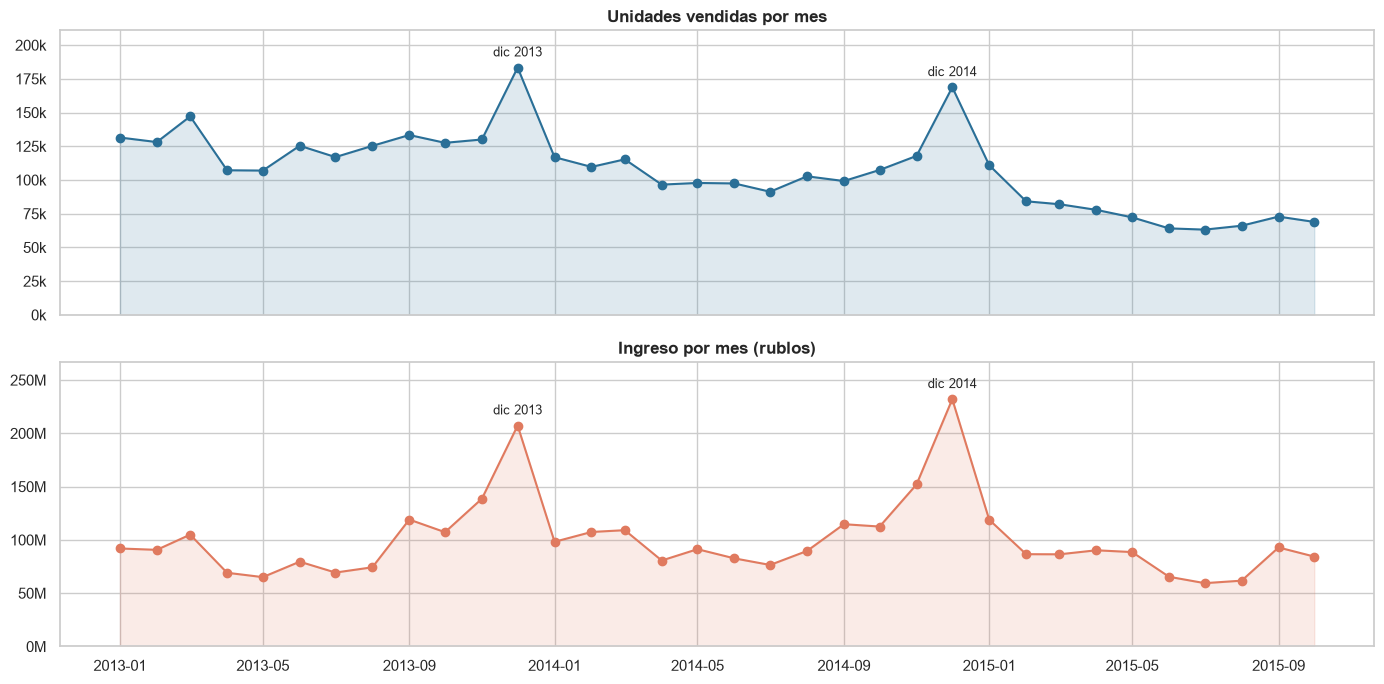

In [27]:
fig, ejes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
for eje, serie, titulo, formato, color in [
    (ejes[0], mensual_total, "Unidades vendidas por mes", MILES, COLOR),
    (ejes[1], ingreso_mensual, "Ingreso por mes (rublos)", MILLONES,
     COLOR_ALT),
]:
    eje.plot(meses_fecha, serie.values, marker="o", color=color)
    eje.fill_between(meses_fecha, serie.values, alpha=0.15, color=color)
    for fecha, valor in zip(meses_fecha, serie.values):
        if fecha.month == 12:
            eje.annotate(f"dic {fecha.year}", (fecha, valor),
                         textcoords="offset points", xytext=(0, 8),
                         ha="center", fontsize=9)
    eje.yaxis.set_major_formatter(formato)
    eje.set_title(titulo)
    eje.set_ylim(0, serie.max() * 1.15)
plt.tight_layout()
plt.show()

### 8.2 Ventas por sucursal

Unidades totales por tienda, coloreadas según si la tienda aparece en `test.csv`.

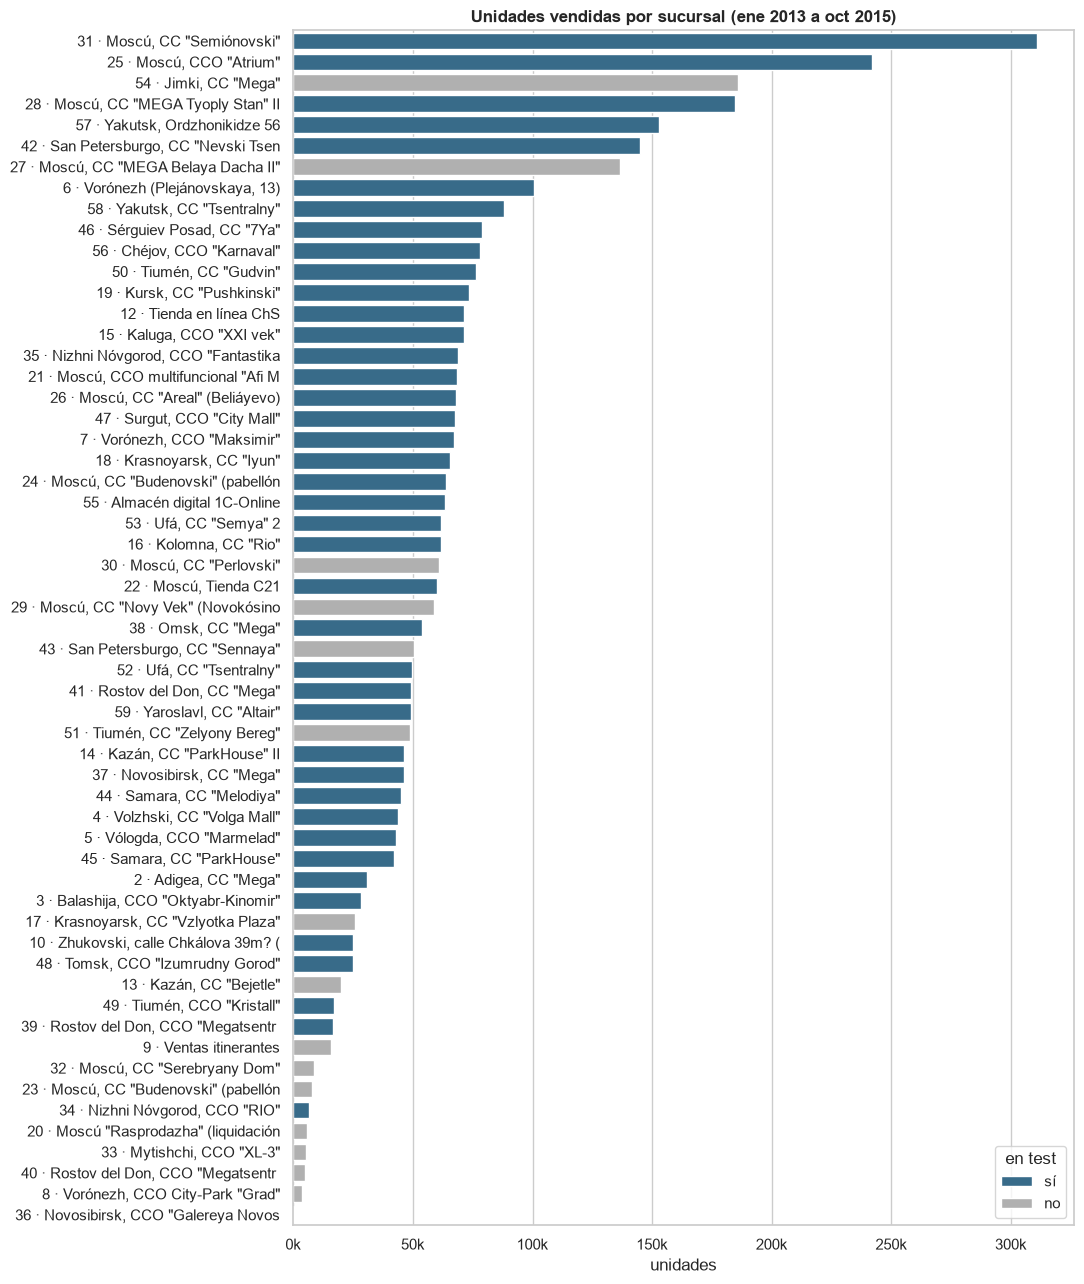

In [28]:
grafico = desempeno.reset_index().sort_values("unidades",
                                              ascending=False)
grafico["etiqueta"] = (grafico["shop_id"].astype(str) + " · "
                       + grafico["shop_name_es"].str.slice(0, 32))
grafico["en test"] = np.where(
    grafico["shop_id"].isin(test["shop_id"].unique()), "sí", "no")
fig, eje = plt.subplots(figsize=(11, 13))
sns.barplot(data=grafico, y="etiqueta", x="unidades", hue="en test",
            dodge=False, palette={"sí": COLOR, "no": "#b0b0b0"}, ax=eje)
eje.xaxis.set_major_formatter(MILES)
eje.set_ylabel("")
eje.set_title("Unidades vendidas por sucursal (ene 2013 a oct 2015)")
plt.tight_layout()
plt.show()

### 8.3 Ventas por producto (top 20) y por categoría

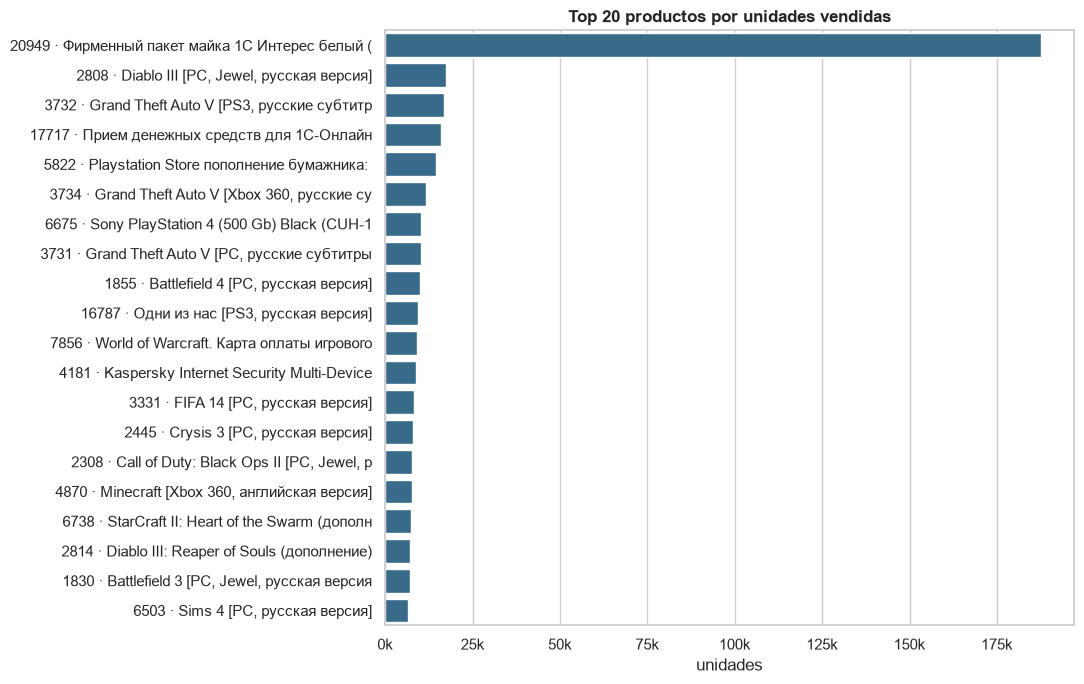

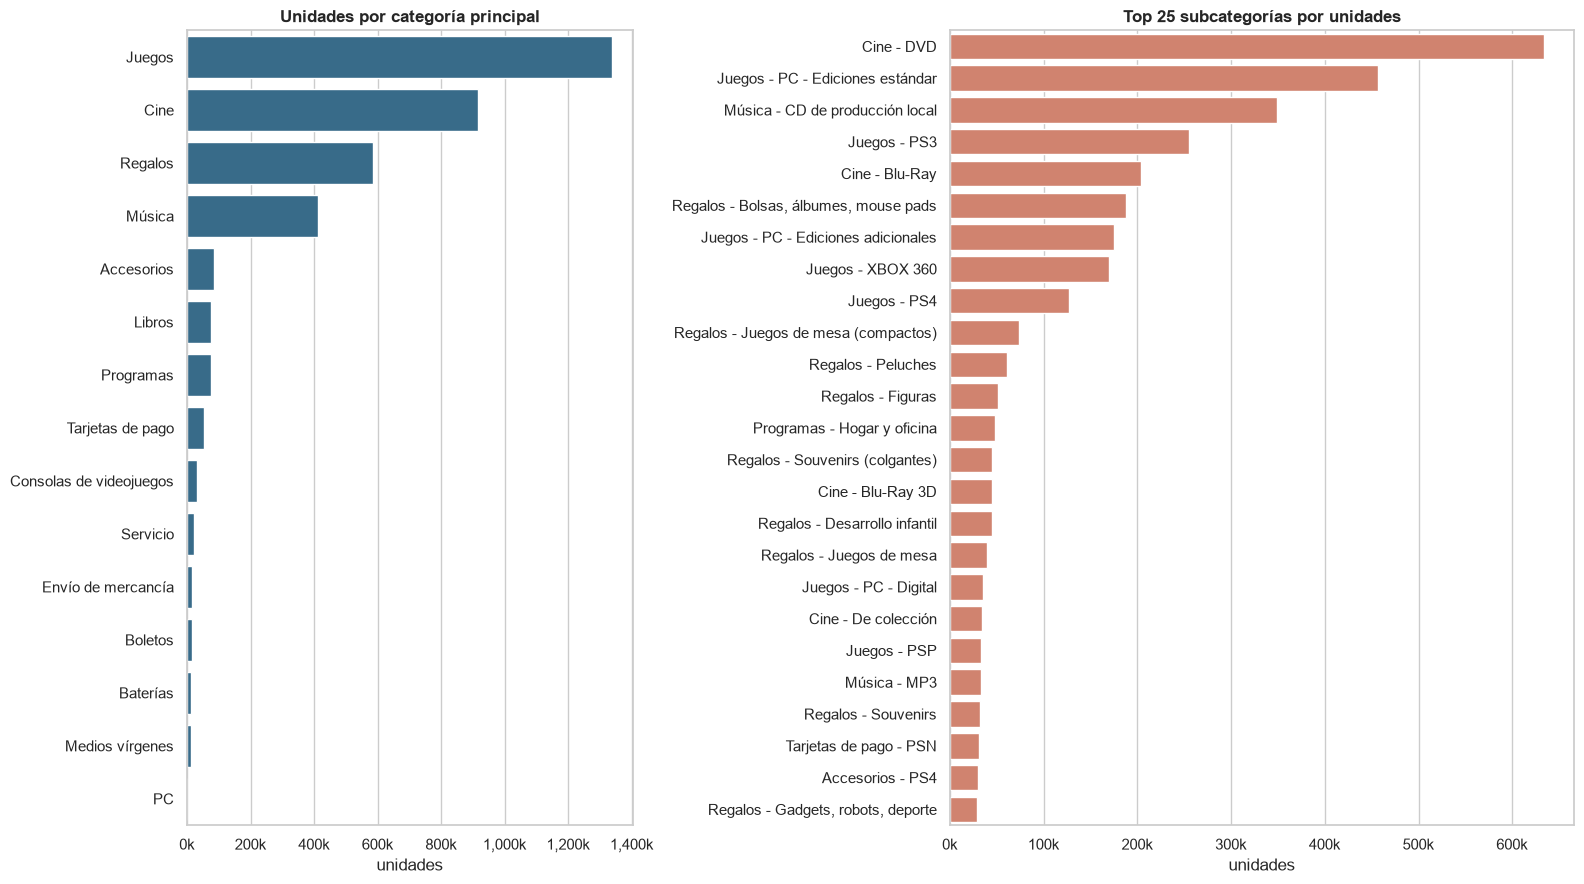

In [29]:
top_items = ranking.nlargest(20, "unidades").copy()
top_items["etiqueta"] = (top_items.index.astype(str) + " · "
                         + top_items["item_name"].str.slice(0, 40))
fig, eje = plt.subplots(figsize=(11, 7))
sns.barplot(data=top_items, y="etiqueta", x="unidades", color=COLOR,
            ax=eje)
eje.xaxis.set_major_formatter(MILES)
eje.set_ylabel("")
eje.set_title("Top 20 productos por unidades vendidas")
plt.tight_layout()
plt.show()

fig, ejes = plt.subplots(1, 2, figsize=(16, 9),
                         gridspec_kw={"width_ratios": [1, 1.4]})
sns.barplot(x=por_categoria["unidades"], y=por_categoria.index,
            color=COLOR, ax=ejes[0])
ejes[0].xaxis.set_major_formatter(MILES)
ejes[0].set_ylabel("")
ejes[0].set_title("Unidades por categoría principal")
top_sub = por_subcategoria.head(25)
sns.barplot(x=top_sub["unidades"], y=top_sub.index, color=COLOR_ALT,
            ax=ejes[1])
ejes[1].xaxis.set_major_formatter(MILES)
ejes[1].set_ylabel("")
ejes[1].set_title("Top 25 subcategorías por unidades")
plt.tight_layout()
plt.show()

### 8.4 Heatmaps: ventas en el tiempo por sucursal y por categoría

Unidades mensuales por tienda y por categoría principal. Las celdas grises son meses sin ventas (tienda cerrada o sin abrir). En el heatmap de categorías, cada fila se normaliza a su propio máximo para comparar la forma de la curva y no el volumen.

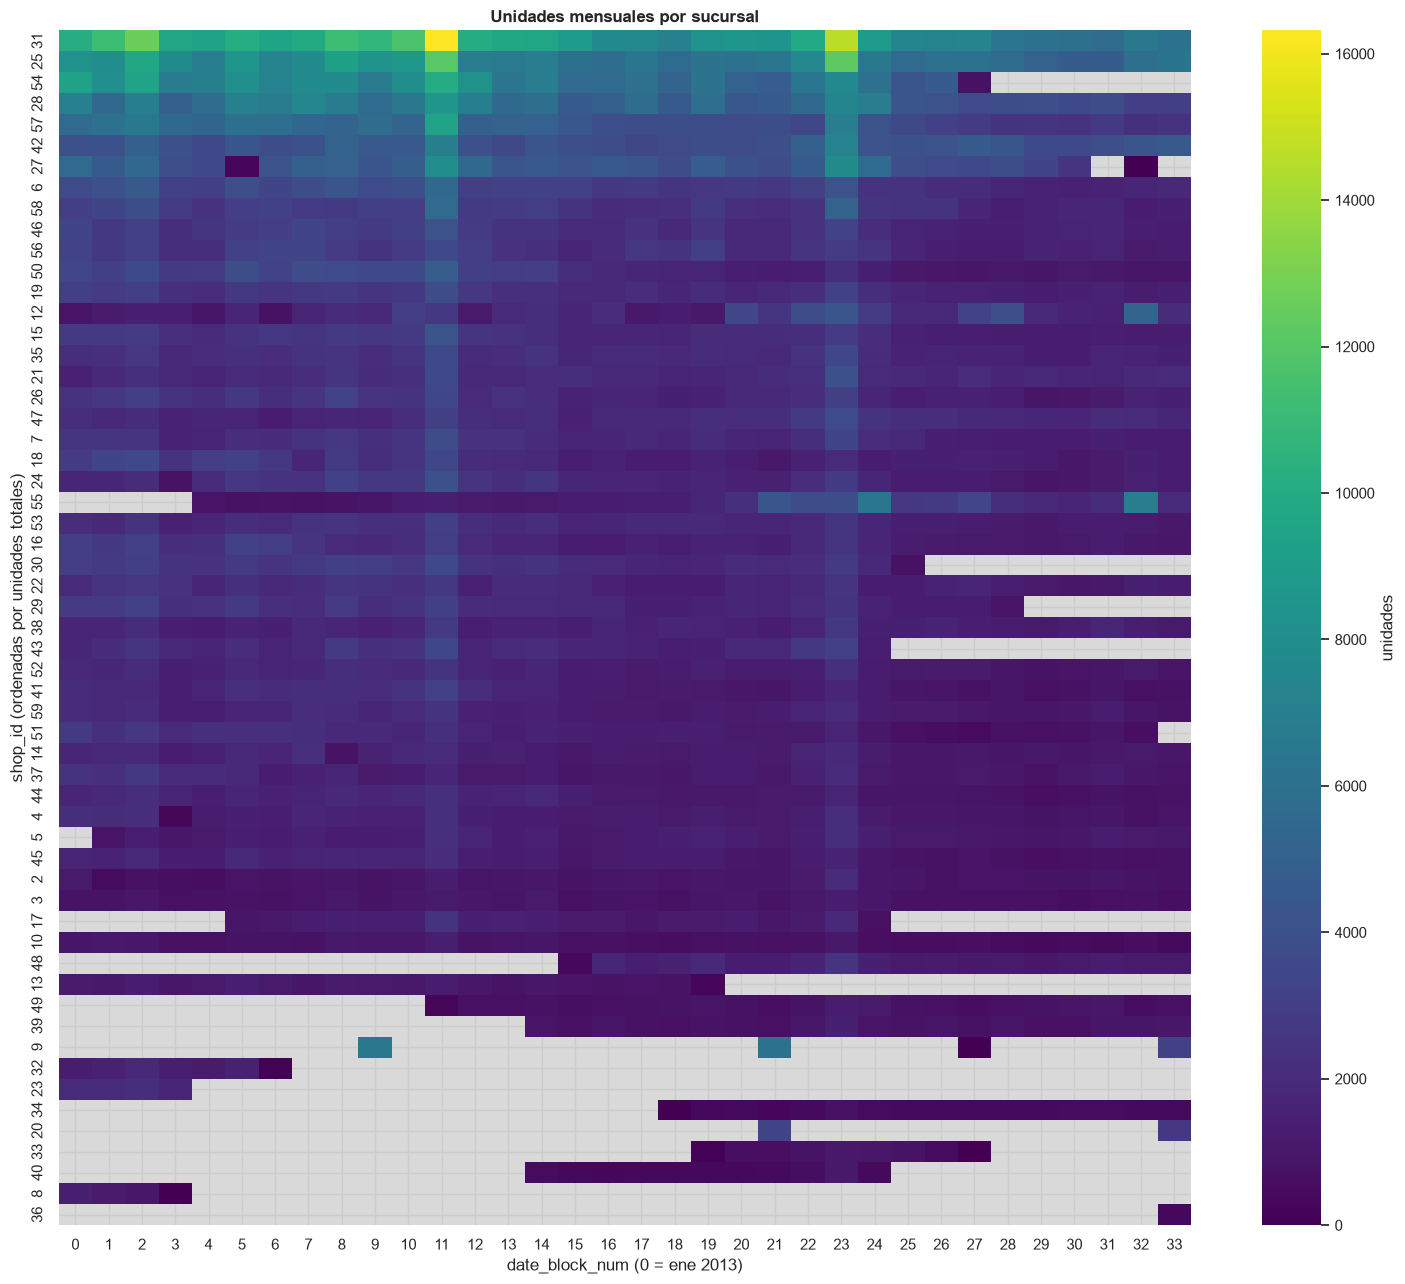

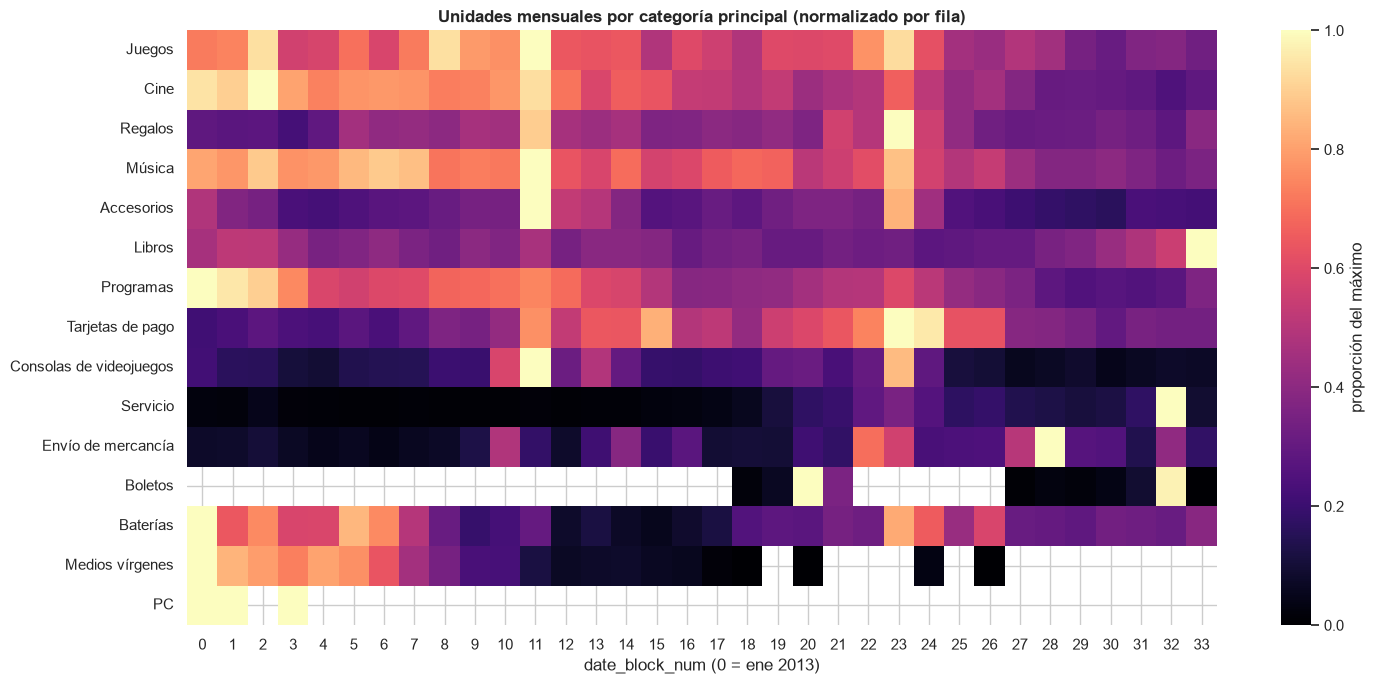

In [30]:
fig, eje = plt.subplots(figsize=(15, 13))
sns.heatmap(tienda_mes.loc[desempeno.index], cmap="viridis",
            mask=tienda_mes.loc[desempeno.index].isna(), yticklabels=True,
            cbar_kws={"label": "unidades"}, ax=eje)
eje.set_facecolor("#d9d9d9")
eje.set_xlabel("date_block_num (0 = ene 2013)")
eje.set_ylabel("shop_id (ordenadas por unidades totales)")
eje.set_title("Unidades mensuales por sucursal")
plt.tight_layout()
plt.show()

categoria_mes = ventas.pivot_table(index="categoria_principal",
                                   columns="date_block_num",
                                   values="item_cnt_day", aggfunc="sum")
categoria_mes = categoria_mes.loc[por_categoria.index]
fig, eje = plt.subplots(figsize=(15, 7))
sns.heatmap(categoria_mes.div(categoria_mes.max(axis=1), axis=0),
            cmap="magma", cbar_kws={"label": "proporción del máximo"},
            ax=eje)
eje.set_xlabel("date_block_num (0 = ene 2013)")
eje.set_ylabel("")
eje.set_title("Unidades mensuales por categoría principal "
              "(normalizado por fila)")
plt.tight_layout()
plt.show()

## 9. Autocorrelación (ACF) y autocorrelación parcial (PACF)

- **ACF:** correlación de la serie con sus rezagos; muestra memoria y estacionalidad.
- **PACF:** correlación con el rezago *k* después de quitar el efecto de los rezagos intermedios; sugiere cuántos términos AR incluir.

Las barras fuera de la banda azul (intervalo de confianza del 95 %) son significativas. Con 34 meses, las series mensuales admiten hasta 16 rezagos en la PACF.

**Selección de series:** la serie total, en frecuencia diaria y mensual; las 3 tiendas con más unidades que vendieron en los 34 meses; los 3 productos con más unidades que vendieron en al menos 30 meses; y los 3 pares tienda-producto con más unidades que vendieron en al menos 30 meses.

In [31]:
LAGS_MES = 16


def graficar_acf_pacf(serie: pd.Series, titulo: str, lags: int) -> None:
    """Grafica la serie, su ACF y su PACF en una fila."""
    fig, ejes = plt.subplots(1, 3, figsize=(17, 3.4))
    ejes[0].plot(serie.index, serie.values, color=COLOR)
    ejes[0].set_title(titulo)
    plot_acf(serie, lags=lags, ax=ejes[1], title="ACF")
    plot_pacf(serie, lags=lags, ax=ejes[2], method="ywm", title="PACF")
    for eje in ejes[1:]:
        eje.set_ylim(-1.1, 1.1)
    plt.tight_layout()
    plt.show()


def rezagos_significativos(serie: pd.Series, lags: int) -> dict:
    """Rezagos fuera del intervalo de confianza del 95 %."""
    resultado = {}
    for nombre, funcion, extra in [("ACF", acf, {"result_object": False}),
                                   ("PACF", pacf, {"method": "ywm"})]:
        valores, intervalo = funcion(serie, nlags=lags, alpha=0.05,
                                     **extra)
        ancho = intervalo[:, 1] - valores
        resultado[nombre] = [k for k in range(1, lags + 1)
                             if abs(valores[k]) > ancho[k]]
    return resultado


def serie_mensual_de(filtro: pd.Series) -> pd.Series:
    """Unidades mensuales (0 a 33) de las filas que cumplen el filtro."""
    return (ventas[filtro].groupby("date_block_num")["item_cnt_day"].sum()
            .reindex(range(34), fill_value=0))


significancia = {}

### 9.1 Serie total: frecuencia diaria y mensual

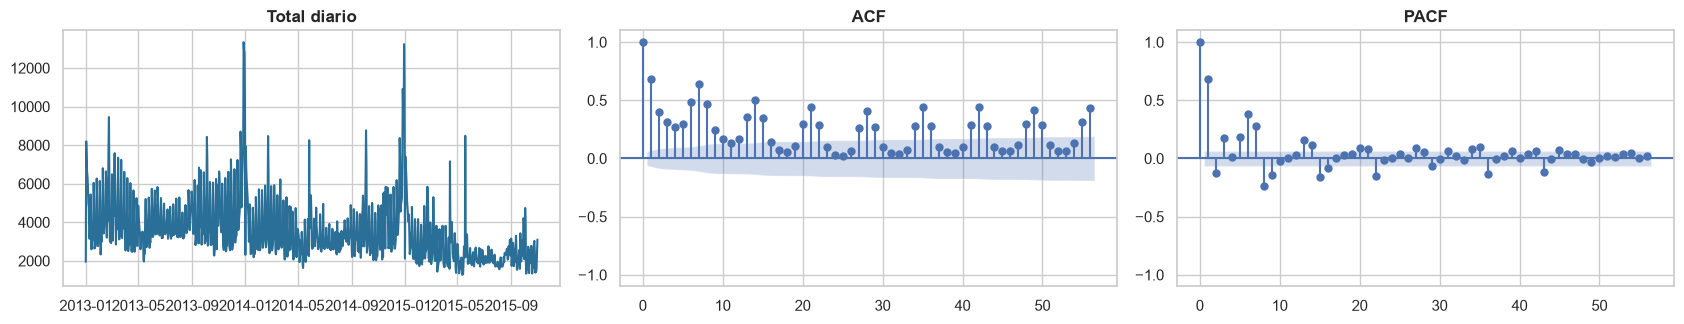

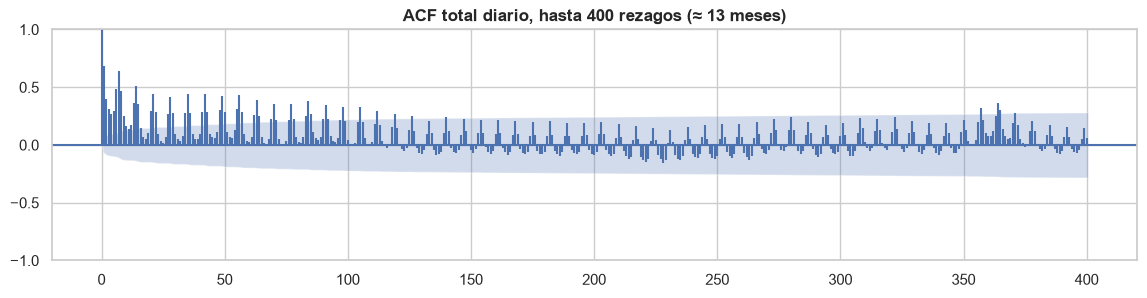

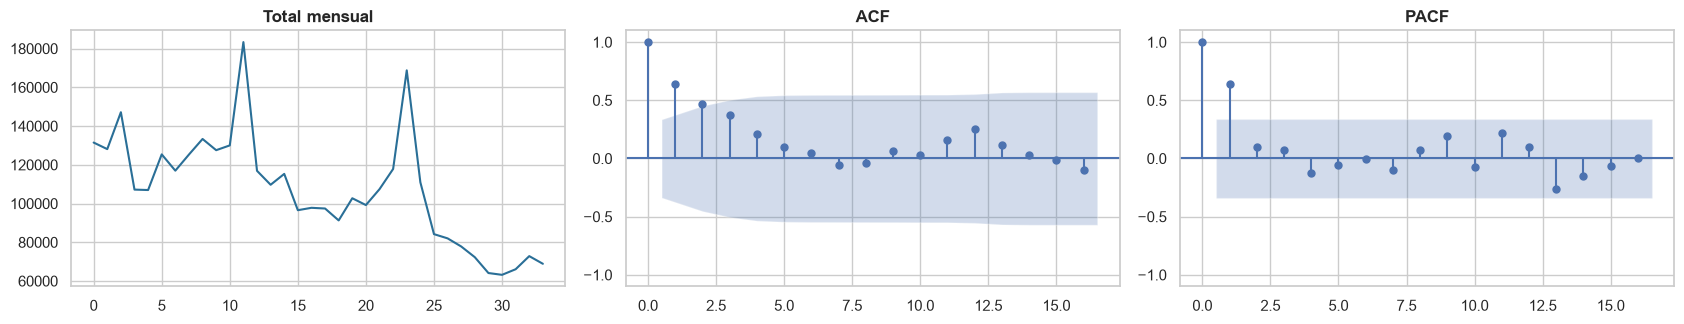

ACF diaria en rezagos clave: {1: 0.68, 6: 0.48, 7: 0.64, 8: 0.47, 14: 0.51, 28: 0.41, 182: 0.2, 364: 0.37, 365: 0.3}
ACF mensual en rezagos clave: {1: 0.64, 2: 0.47, 3: 0.37, 6: 0.05, 12: 0.26}


In [32]:
serie_diaria = diaria.asfreq("D", fill_value=0)
graficar_acf_pacf(serie_diaria, "Total diario", lags=56)
significancia["Total diario"] = rezagos_significativos(serie_diaria, 56)

fig, eje = plt.subplots(figsize=(14, 3))
plot_acf(serie_diaria, lags=400, ax=eje, marker=None,
         title="ACF total diario, hasta 400 rezagos (≈ 13 meses)")
plt.show()

graficar_acf_pacf(mensual_total, "Total mensual", lags=LAGS_MES)
significancia["Total mensual"] = rezagos_significativos(mensual_total,
                                                        LAGS_MES)

acf_diaria = acf(serie_diaria, nlags=400, result_object=False)
acf_mensual = acf(mensual_total, nlags=LAGS_MES, result_object=False)
print("ACF diaria en rezagos clave:",
      {k: round(float(acf_diaria[k]), 2)
       for k in (1, 6, 7, 8, 14, 28, 182, 364, 365)})
print("ACF mensual en rezagos clave:",
      {k: round(float(acf_mensual[k]), 2) for k in (1, 2, 3, 6, 12)})

### 9.2 Series por sucursal

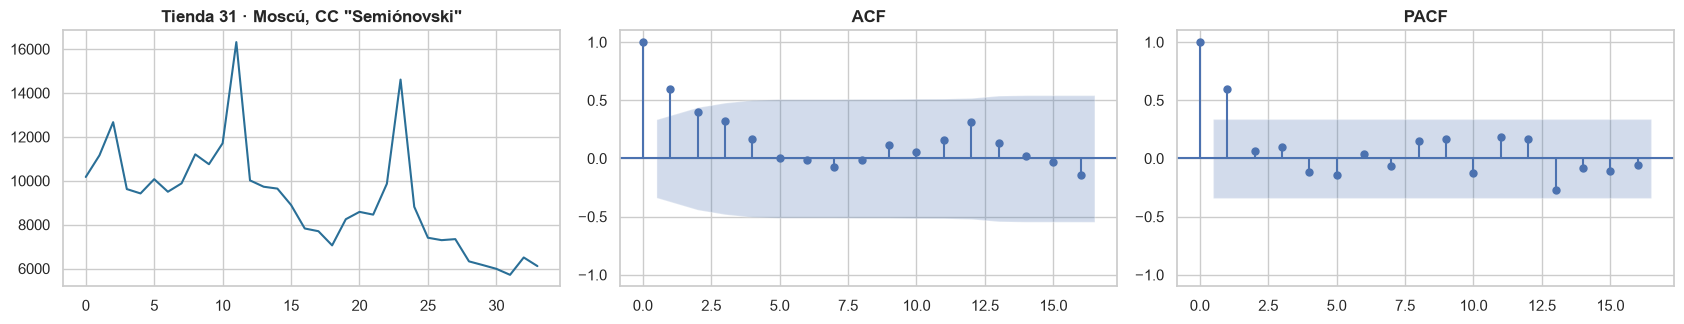

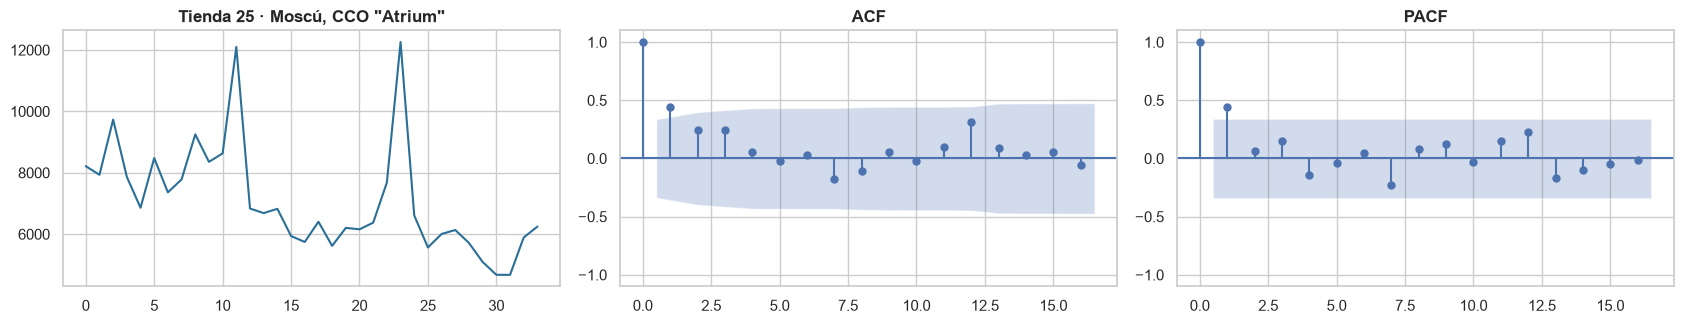

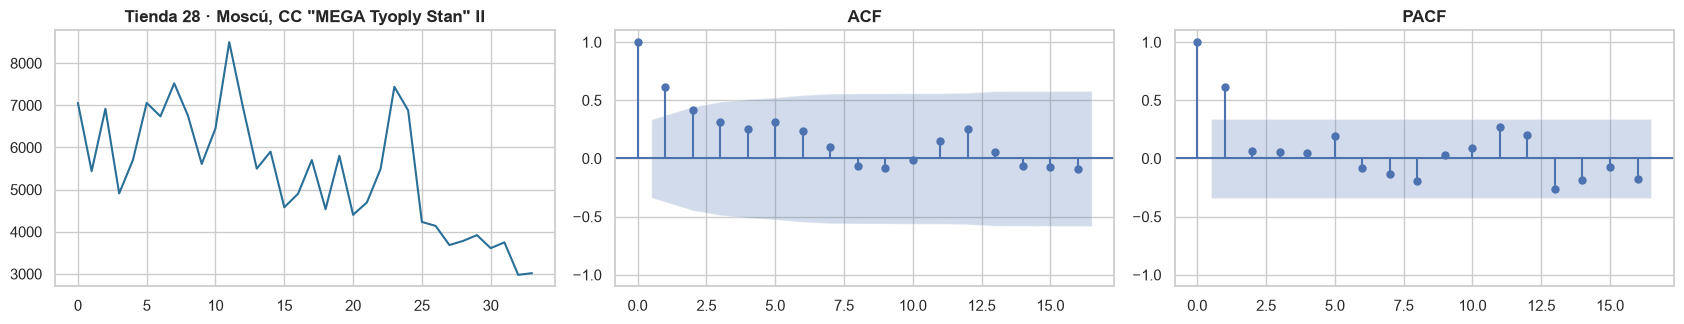

In [33]:
meses_tienda = ventas.groupby("shop_id")["date_block_num"].nunique()
top_tiendas = (ventas[ventas["shop_id"].isin(
    meses_tienda[meses_tienda == 34].index)]
    .groupby("shop_id")["item_cnt_day"].sum().nlargest(3).index)
for tienda in top_tiendas:
    nombre = f"Tienda {tienda} · {tiendas_es.loc[tienda, 'shop_name_es']}"
    serie = serie_mensual_de(ventas["shop_id"] == tienda)
    graficar_acf_pacf(serie, nombre[:45], lags=LAGS_MES)
    significancia[f"Tienda {tienda}"] = rezagos_significativos(serie,
                                                               LAGS_MES)

### 9.3 Series por producto

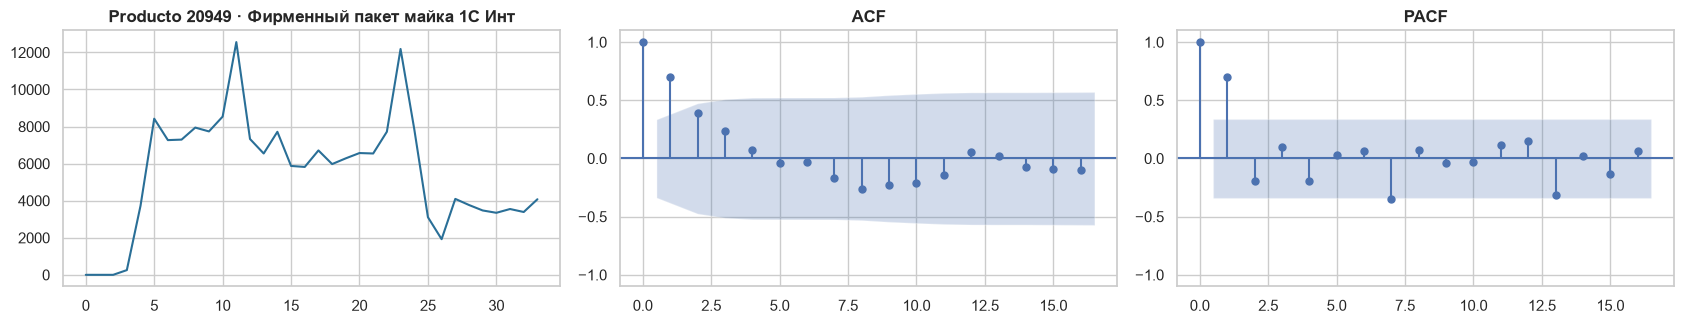

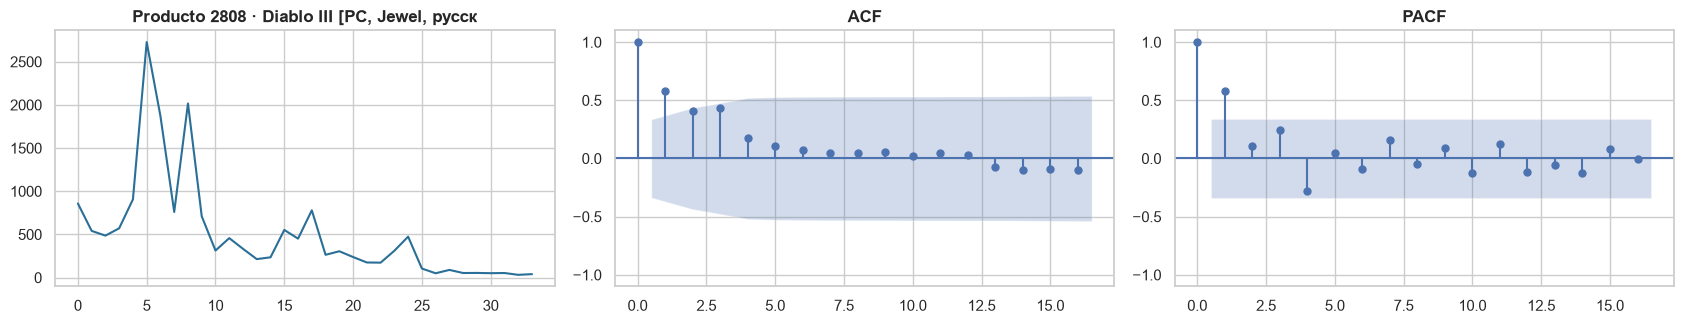

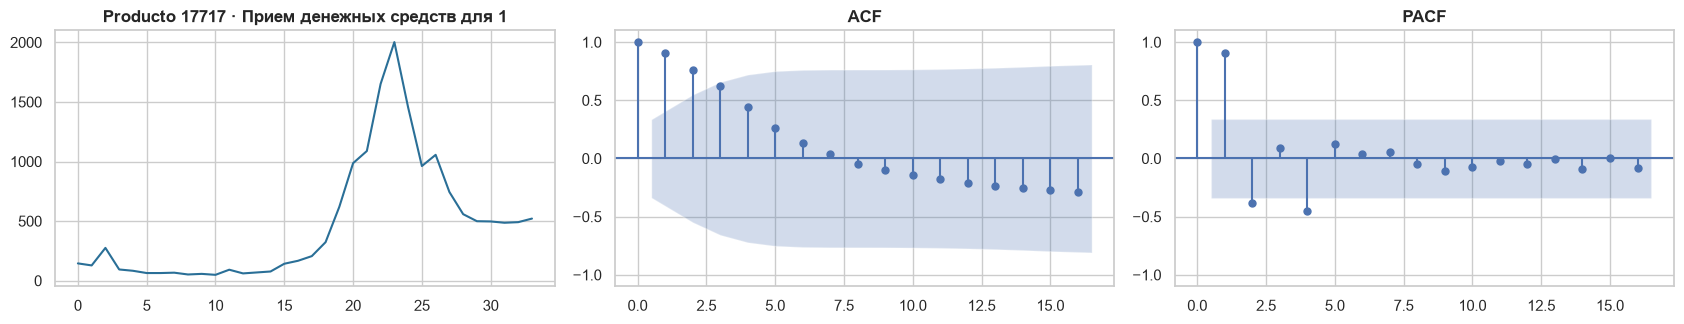

In [34]:
top_productos = (por_item[por_item["meses_con_venta"] >= 30]
                 .nlargest(3, "unidades").index)
for producto in top_productos:
    serie = serie_mensual_de(ventas["item_id"] == producto)
    graficar_acf_pacf(serie, f"Producto {producto} · "
                      f"{nombres[producto][:28]}", lags=LAGS_MES)
    significancia[f"Producto {producto}"] = rezagos_significativos(
        serie, LAGS_MES)

### 9.4 Series por par sucursal-producto

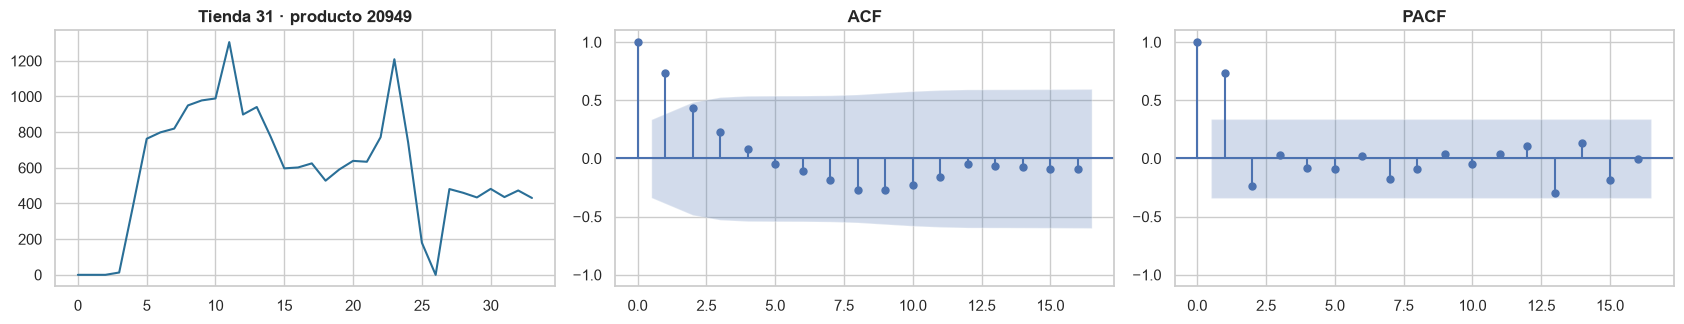

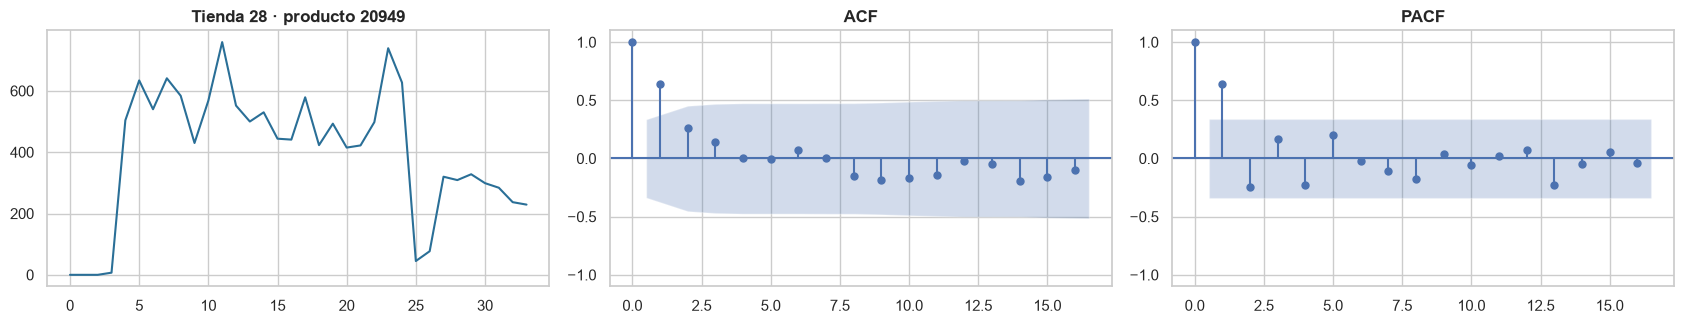

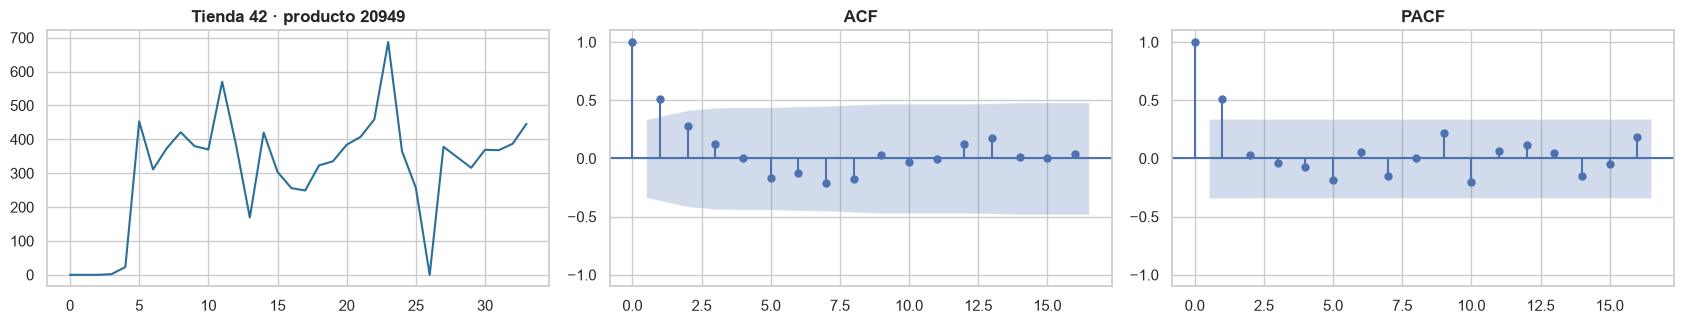

In [35]:
por_par = ventas.groupby(["shop_id", "item_id"]).agg(
    unidades=("item_cnt_day", "sum"),
    meses=("date_block_num", "nunique"))
top_pares = por_par[por_par["meses"] >= 30].nlargest(3, "unidades").index
for tienda, producto in top_pares:
    serie = serie_mensual_de((ventas["shop_id"] == tienda)
                             & (ventas["item_id"] == producto))
    graficar_acf_pacf(serie, f"Tienda {tienda} · producto {producto}",
                      lags=LAGS_MES)
    significancia[f"Tienda {tienda} · producto {producto}"] = (
        rezagos_significativos(serie, LAGS_MES))

### 9.5 Resumen de rezagos significativos

In [36]:
pd.DataFrame(significancia).T.map(
    lambda rezagos: ", ".join(map(str, rezagos[:15])) or "ninguno")

,ACF,PACF
Total diario,"1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15","1, 2, 3, 5, 6, 7, 8, 9, 13, 14, 15, 16, 20, 21..."
Total mensual,"1, 2",1
Tienda 31,1,1
Tienda 25,1,1
Tienda 28,1,1
Producto 20949,1,"1, 7"
Producto 2808,1,1
Producto 17717,"1, 2","1, 2, 4"
Tienda 31 · producto 20949,1,1
Tienda 28 · producto 20949,1,1


### 9.6 Interpretación

**i. ¿Existen correlaciones significativas en distintos rezagos?**

- **Total diario:**
  - La ACF es significativa en todos los rezagos hasta el 56 y decae muy despacio (0.68 en el rezago 1, 0.41 en el 28): la serie tiene memoria larga y tendencia, otra señal de que no es estacionaria.
  - La PACF tiene sus picos más fuertes en los primeros rezagos y alrededor de los múltiplos de 7. Eso sugiere un componente AR de orden bajo más un término estacional semanal.
- **Total mensual:** la ACF es significativa en los rezagos 1 y 2 (0.64 y 0.47) y decae de forma gradual; la PACF solo es significativa en el rezago 1. Es el patrón de un proceso **AR(1)**.
- **Tiendas, productos y pares tienda-producto:** casi todas las series repiten el patrón, con ACF y PACF significativas solo en el rezago 1. El producto 17717 agrega los rezagos 2 y 4 en la PACF, y el 20949 el rezago 7. **La mejor información sobre las ventas del próximo mes son las ventas del mes anterior.**

**ii. ¿Se observa estacionalidad?**

- **Semanal:** muy clara en la serie diaria. La ACF sube en cada múltiplo de 7 (0.64 en el rezago 7 frente a 0.48 y 0.47 en el 6 y el 8).
- **Anual:** se ve en la gráfica (picos de diciembre) y en la ACF diaria, que repunta cerca del rezago 364 (0.37). En la ACF mensual el rezago 12 sube a 0.26, pero **no es significativo**: con solo 34 meses (dos ciclos y medio) la banda de confianza es muy ancha. Aun así, en la malla de la sección 10.2 las ventas de hace 12 meses tienen una correlación de 0.51 con el target sin recortar, así que el rezago 12 vale como feature candidata.

**Implicación para el modelo:** incluir rezagos de 1 a 3 meses (y el 12 como candidato) y variables de calendario (mes del año, número de días y de fines de semana del mes).

## 10. Insights y conclusiones del EDA

### 10.1 Cobertura de `test.csv` en el historial

Cada fila de test se clasifica en uno de tres grupos: el par tienda-producto tiene historial; el producto se vendió solo en otras tiendas; o el producto nunca se vendió (es nuevo).

In [37]:
pares_train = ventas[["shop_id", "item_id"]].drop_duplicates()
cobertura = test.merge(pares_train, how="left", indicator="par")
cobertura["item_visto"] = cobertura["item_id"].isin(ventas["item_id"])
cobertura["grupo"] = np.select(
    [cobertura["par"] == "both", cobertura["item_visto"]],
    ["par con historial", "producto visto en otra tienda"],
    "producto nuevo",
)
resumen_test = cobertura["grupo"].value_counts().to_frame("filas")
resumen_test["%"] = resumen_test["filas"] / len(test) * 100
display(resumen_test)

recientes = ventas.loc[ventas["date_block_num"] >= 28,
                       ["shop_id", "item_id"]].drop_duplicates()
print(f"Pares de test con venta en los últimos 6 meses: "
      f"{test.merge(recientes).shape[0] / len(test):.1%}")
print(f"Tiendas en test: {test['shop_id'].nunique()} | productos: "
      f"{test['item_id'].nunique():,} | filas: {len(test):,} = "
      f"tiendas × productos: "
      f"{test['shop_id'].nunique() * test['item_id'].nunique() == len(test)}")
nuevos = test.loc[~test["item_id"].isin(ventas["item_id"]), "item_id"]
print("Categorías de los productos nuevos en test:")
display(items[items["item_id"].isin(nuevos)]
        .merge(categorias_es[["item_category_id", "categoria_principal"]])
        ["categoria_principal"].value_counts().head(8).to_frame())

,filas,%
grupo,,
par con historial,111471,52.04
producto visto en otra tienda,87483,40.84
producto nuevo,15246,7.12


Pares de test con venta en los últimos 6 meses: 34.8%
Tiendas en test: 42 | productos: 5,100 | filas: 214,200 = tiendas × productos: True
Categorías de los productos nuevos en test:


,count
categoria_principal,
Juegos,84
Cine,74
Regalos,67
Música,66
Libros,44
Programas,18
Consolas de videojuegos,6
Accesorios,2


### 10.2 Variables que afectan las ventas

Para medir la relación con el target se arma una **malla** como la de test: para cada mes de 2014-11 a 2015-10 (meses 22 a 33), todas las combinaciones de las tiendas activas por los productos vendidos ese mes, con 0 donde no hubo venta. Sobre esa malla se calcula:

- **Pearson** del target con las variables numéricas: ventas del mismo par en los meses anteriores (rezagos 1, 2, 3 y 12), precio y antigüedad del producto;
- **razón de correlación η** con las categóricas (η² equivale al R² de un ANOVA de un factor).

Se reporta con el target recortado a [0, 20] y sin recortar.

In [38]:
MESES_MALLA = range(22, 34)
malla = pd.concat(
    [
        pd.MultiIndex.from_product(
            [[mes],
             ventas.loc[ventas["date_block_num"] == mes, "shop_id"].unique(),
             ventas.loc[ventas["date_block_num"] == mes, "item_id"].unique()],
            names=claves,
        ).to_frame(index=False)
        for mes in MESES_MALLA
    ],
    ignore_index=True,
)
malla = malla.merge(mensual, on=claves, how="left").fillna(
    {"item_cnt_month": 0})
for lag in (1, 2, 3, 12):
    previo = mensual.assign(date_block_num=mensual["date_block_num"] + lag)
    malla = malla.merge(previo.rename(
        columns={"item_cnt_month": f"ventas_lag_{lag}"}), on=claves,
        how="left").fillna({f"ventas_lag_{lag}": 0})

primera_venta = mensual.groupby("item_id")["date_block_num"].min()
malla["meses_desde_lanzamiento"] = (malla["date_block_num"]
                                    - malla["item_id"].map(primera_venta))
malla["log_precio_mediano"] = np.log1p(
    malla["item_id"].map(precio_item["median"]))
malla = (malla
         .merge(items[["item_id", "item_category_id"]], on="item_id")
         .merge(categorias_es[["item_category_id", "categoria_principal",
                               "es_digital"]], on="item_category_id")
         .merge(tiendas_es[["shop_id", "ciudad", "tipo_tienda"]],
                on="shop_id"))
malla["mes_del_anio"] = malla["date_block_num"] % 12 + 1
malla["target_recortado"] = malla["item_cnt_month"].clip(0, 20)
print(f"Filas de la malla: {len(malla):,} | % de ceros en el target: "
      f"{(malla['item_cnt_month'] == 0).mean():.1%}")


def razon_correlacion(grupos: pd.Series, valores: pd.Series) -> float:
    """Razón de correlación η entre una categórica y una numérica."""
    medias = valores.groupby(grupos).transform("mean")
    ss_entre = ((medias - valores.mean()) ** 2).sum()
    ss_total = ((valores - valores.mean()) ** 2).sum()
    return float(np.sqrt(ss_entre / ss_total))


NUMERICAS = ["ventas_lag_1", "ventas_lag_2", "ventas_lag_3",
             "ventas_lag_12", "meses_desde_lanzamiento",
             "log_precio_mediano", "es_digital"]
CATEGORICAS = ["item_category_id", "categoria_principal", "shop_id",
               "ciudad", "tipo_tienda", "mes_del_anio"]
filas = []
for var in NUMERICAS + CATEGORICAS:
    fila = {"variable": var,
            "metrica": "Pearson r" if var in NUMERICAS else "η"}
    for target in ("target_recortado", "item_cnt_month"):
        if var in NUMERICAS:
            fila[target] = malla[var].corr(malla[target])
        else:
            fila[target] = razon_correlacion(malla[var], malla[target])
    filas.append(fila)
relacion = (pd.DataFrame(filas)
            .assign(orden=lambda d: d["target_recortado"].abs())
            .sort_values("orden", ascending=False).drop(columns="orden"))
relacion

Filas de la malla: 3,131,927 | % de ceros en el target: 85.4%


,variable,metrica,target_recortado,item_cnt_month
0,ventas_lag_1,Pearson r,0.34,0.55
7,item_category_id,η,0.32,0.35
1,ventas_lag_2,Pearson r,0.29,0.45
2,ventas_lag_3,Pearson r,0.26,0.43
3,ventas_lag_12,Pearson r,0.20,0.51
9,shop_id,η,0.18,0.07
8,categoria_principal,η,0.16,0.08
10,ciudad,η,0.13,0.05
4,meses_desde_lanzamiento,Pearson r,-0.09,-0.03
5,log_precio_mediano,Pearson r,0.06,0.01


### 10.3 Conclusiones

**Variables que afectan directamente las ventas** (sección 10.2)

1. **Ventas pasadas del mismo par tienda-producto** (rezagos 1, 2, 3 y 12): son la relación más fuerte. El rezago 1 tiene r = 0.34 con el target recortado y 0.55 sin recortar.
2. **Categoría del producto:** `item_category_id` tiene η = 0.32. La subcategoría explica el doble que la categoría principal (η = 0.16).
3. **Tienda y ciudad:** η = 0.18 y 0.13.
4. **Antigüedad del producto:** los productos recientes venden más (r negativa con los meses desde el lanzamiento).

A nivel par-mes, el precio, el formato digital, el mes del año y el tipo de tienda tienen una relación débil. La estacionalidad sí pesa a nivel agregado (diciembre y noviembre).

**Patrones útiles para el forecasting**

- **Problema mensual y muy disperso:** en la malla tienda × producto, el **85 % de las celdas es 0**. El modelo debe entrenarse sobre una malla como la de test (todas las combinaciones de tiendas y productos activos de cada mes), no solo sobre los pares con venta.
- **Cobertura de test:**
  - el **52 %** de los pares tiene historial;
  - el **41 %** son productos que sí se vendieron, pero en otras tiendas;
  - el **7 %** (15,246 filas, 363 productos) son productos nuevos, sin ningún historial.

  Para los dos últimos grupos los rezagos del par valen 0, así que el modelo tiene que apoyarse en features del producto (categoría, ventas en otras tiendas, texto del nombre) y de la tienda. Solo el 35 % de los pares de test vendió algo en los últimos 6 meses.
- **Features candidatas más fuertes:** las ventas del par en meses anteriores y los promedios por producto, tienda y categoría, todos con rezago para no filtrar información del futuro.
- **Tendencia y estacionalidad:** la tendencia es descendente, con pico en diciembre y alza en noviembre. El mes del año y el número de fines de semana del mes son features de calendario útiles.
- **Target muy sesgado:** el máximo es 1,644 y el 0.7 % supera 20. El recorte a [0, 20] baja las correlaciones (el rezago 12 pasa de 0.51 a 0.20), pero refleja cómo evalúa Kaggle. **La decisión del recorte queda para la fase 2.**
- **Casos especiales:** las tiendas especiales (en línea 12 y 55, itinerante 9, liquidación 20) y los productos atípicos (la bolsa 20949, los boletos de IgroMir) se comportan distinto y conviene marcarlos.

**Calidad y preparación del dataset**

- **Buena calidad estructural:** sin nulos, sin días faltantes, `date_block_num` consistente, IDs únicos y catálogos completos.
- **Problemas menores, resueltos en memoria y documentados para la fase 2:** 6 duplicados exactos, 3 filas inválidas o extremas, 3 tiendas repetidas (0→57, 1→58, 11→10) y 7,356 devoluciones que se netean al agregar.
- **Retos para el modelado:**
  - el target no existe y hay que construirlo;
  - la malla es muy dispersa;
  - hay productos nuevos, y tiendas que abren y cierran;
  - la estacionalidad anual tiene pocas observaciones (34 meses).
- **Texto en ruso:** las tiendas y las categorías tienen traducción manual; `item_name` queda como fuente de features de texto para la fase 2.